# Практическое занятие №1. Логистическая регрессия

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Датасет **Breast Cancer Wisconsin (Diagnostic)** из `sklearn.datasets`: 569
цифровых снимков ядер клеток молочной железы, сделанных в 1989-1995 годах в
Университете Висконсина (США) с помощью обычного светового микроскопа.
Каждый снимок - ядро одной клетки, описанное **30 числовыми признаками**, а
цель - был ли диагноз злокачественным.

Задача - **бинарная классификация**: по 30 измерениям ядра клетки определить,
злокачественная это опухоль или доброкачественная.

Что делаем и зачем:

1. **Данные** - загружаем датасет одной командой `load_breast_cancer()` и
   разбираем, как устроены 30 признаков.
2. **Проверка и очистка** - дубликаты, пропуски, аномалии. Даже если датасет
   чистый, код проверки обязателен: он показывает, что мы действительно
   смотрели на данные, а не просто начинали с ними работу.
3. **Разведочный анализ** - распределения, связь признаков с диагнозом и
   корреляции между самими признаками.
4. **Подготовка** - стандартизация и разделение на train / validation / test.
5. **Модель** - логистическая регрессия, у которой читаются коэффициенты.
6. **Обучение** - обучение на train и проверка переобучения по validation.
7. **Оценка** - метрики, сравнение с базовой линией, выбор порога, разбор
   ошибок.
8. **Выводы** - что получилось, где модель ошибается и чего работе не хватает.

## Почему логистическая регрессия

Цель имеет ровно два класса, все признаки числовые, а сама задача медицинская,
где цена ошибки асимметрична: пропущенная злокачественная опухоль опаснее
лишнего обследования. Логистическая регрессия подходит лучше всего:

* коэффициенты **читаются** - это не «черный ящик», знак коэффициента прямо
  говорит, повышает или понижает вероятность злокачественности;
* модель выдаёт **вероятность**, а не жёсткую метку, поэтому порог принятия
  решения можно выбирать отдельно от обучения;
* у неё честное правило подбора: минимум взвешенной логарифмической потери,
  а не «как получилось».

Работа построена так, чтобы результат был **честным**: порог подбирается по
валидационной выборке, тестовая используется один раз в самом конце.


In [1]:
# Ячейка 1 - зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, - иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("numpy", "pandas", "sklearn", "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла: так сразу видно,
# на чём построена работа, и ниже по ноутбуку нигде не появляется
# «внезапный» импорт.
import numpy as np                         # численные массивы, сетка порогов, матрицы
import pandas as pd                        # таблицы: типы, статистика, сводные срезы

import matplotlib.pyplot as plt             # базовые графики
import seaborn as sns                       # читаемые графики и тепловая карта корреляций

from sklearn.datasets import load_breast_cancer        # официальный загрузчик датасета
from sklearn.model_selection import (                  # разделение выборок и устойчивая оценка
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.preprocessing import StandardScaler       # стандартизация числовых признаков
from sklearn.pipeline import Pipeline                  # «преобразования + модель», чтобы не было утечки
from sklearn.linear_model import LogisticRegression    # сама модель работы
from sklearn.dummy import DummyClassifier              # базовая линия: всегда один и тот же класс
from sklearn.metrics import (                          # метрики качества бинарной классификации
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    precision_recall_curve,
)


In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел, иначе каждый запуск
# ноутбука давал бы немного разные разбиения и метрики.
SEED = 42
np.random.seed(SEED)

# Графики должны попадать в вывод ноутбука как картинки - это делает inline-режим.
%matplotlib inline

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)


## 1. Данные

**Breast Cancer Wisconsin (Diagnostic)** - открытый набор для бинарной
классификации, который входит в `sklearn.datasets`. Файл с данными уже лежит
в пакете `scikit-learn`, поэтому датасет воспроизводится одной командой без
ручного скачивания: ноутбук одинаково запускается на любой машине и в облаке.

Схема данных: **569 строк, 30 числовых признаков, 1 целевая переменная**.
Каждая строка - одно ядро клетки, измеренное по цифровому снимку: цветовая
текстура, форма, чёткость границы. Все 30 признаков **числовые** - кодировать
категории нечего, но проверять это мы всё равно обязаны.

30 признаков - это не 30 разных характеристик. Это **10 измерений,
посчитанных тремя способами**, отсюда и 3 блока по 10 признаков:

| Блок | Как называется | Что значит |
|---|---|---|
| `mean ...` | средние | среднее по всем ядрам, найденным на снимке |
| `... error` | ошибки | стандартное отклонение внутри снимка: насколько ядра различаются между собой |
| `worst ...` | худшие | значения для **самой неблагоприятной** ячейки на снимке |

Например, `mean radius`, `radius error` и `worst radius` - это три разных
числа про одну и ту же характеристику (размер ядра): среднее, разброс и худший
случай. Именно так устроен набор: один биопсийный препарат даёт сразу 10
измерений, и каждое описывается тремя числами.

Почему этот датасет выбран:

* **дисбаланс классов**: 357 доброкачественных против 212 злокачественных.
  Accuracy около 0.97 вводит в заблуждение, и это надо честно показать;
* **сильная мультиколлинеарность**: размер, периметр и площадь ядра почти
  линейно зависят друг от друга (корреляция выше 0.98). Это даёт сильный
  материал для раздела про коэффициенты и про то, почему они нестабильны;
* **все признаки в разном масштабе**: площадь измеряется тысячами, гладкость
  границы - долями. Стандартизация обязательна;
* **медицинская цена ошибки асимметрична**, поэтому порог выбирается осмысленно.


In [4]:
# Загрузка: load_breast_cancer отдаёт готовый датасет из пакета sklearn,
# интернет для этого не нужен. Это принципиально удобнее ручной загрузки с
# сайта: результат не зависит от доступности внешнего источника.
cancer = load_breast_cancer()

# Собираем таблицу: матрица признаков лежит в cancer.data, целевая переменная
# в cancer.target, имена столбцов - в cancer.feature_names. Отдельный DataFrame
# удобнее структурного массива numpy: сразу есть имена, типы и методы анализа.
FEATURE_COLUMNS = list(cancer.feature_names)

data = pd.DataFrame(cancer.data, columns=FEATURE_COLUMNS)
data["target"] = cancer.target

print(f"объект: {type(cancer).__name__}, строк: {len(data)}, признаков: {len(FEATURE_COLUMNS)}")
print(f"источник: пакет sklearn.datasets, сеть не требуется")
# target_names приходит массивом numpy, поэтому приводим элементы к обычным
# строкам: без этого в выводе появляется служебная обёртка np.str_(...).
class_names_source = [str(name) for name in cancer.target_names]
print(f"имена классов в исходной разметке: {class_names_source}")
print()
print("первые 4 строки и 4 признака:")
data[FEATURE_COLUMNS[:4] + ["target"]].round(3)


объект: Bunch, строк: 569, признаков: 30
источник: пакет sklearn.datasets, сеть не требуется
имена классов в исходной разметке: ['malignant', 'benign']

первые 4 строки и 4 признака:


,mean radius,mean texture,mean perimeter,mean area,target
0,17.99,10.38,122.80,1001.0,0
1,20.57,17.77,132.90,1326.0,0
2,19.69,21.25,130.00,1203.0,0
3,11.42,20.38,77.58,386.1,0
4,20.29,14.34,135.10,1297.0,0
...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0
565,20.13,28.25,131.20,1261.0,0
566,16.60,28.08,108.30,858.1,0
567,20.60,29.33,140.10,1265.0,0


In [5]:
# Разбираем структуру 30 признаков. Описание каждого по отдельности заняло бы
# 30 строк таблицы и ничего бы не добавило: все они устроены одинаково.
# Полезнее понять правило, по которому они построены.
BLOCKS = ("mean", "error", "worst")
BLOCK_LABELS = {
    "mean": "средние (mean)",
    "error": "ошибки (error)",
    "worst": "худшие (worst)",
}

def feature_block(name):
    """Возвращает блок измерений, к которому относится признак."""
    if name.startswith("mean "):
        return "mean"
    if name.endswith(" error"):
        return "error"
    if name.startswith("worst "):
        return "worst"
    return "прочее"


def measurement_name(name):
    """Отбрасывает префикс блока и возвращает название самого измерения."""
    if name.startswith("mean "):
        return name[5:]
    if name.endswith(" error"):
        return name[:-6]
    if name.startswith("worst "):
        return name[6:]
    return name


layout = pd.DataFrame({
    "признак": FEATURE_COLUMNS,
    "блок": [feature_block(name) for name in FEATURE_COLUMNS],
    "измерение": [measurement_name(name) for name in FEATURE_COLUMNS],
})

print("признаков в каждом блоке:")
print(layout["блок"].value_counts().to_frame("признаков"))
print()
print("каждый блок описывает одни и те же 10 измерений:")
print(layout.groupby("блок")["измерение"].nunique().to_frame("разных измерений"))

# Проверка структуры: если бы порядок блоков в датасете отличался от ожидаемого,
# здесь было бы исключение, и мы узнали бы об этом сразу, а не по факту ошибки
# в разборе коэффициентов.
assert sorted(layout[layout["блок"] != "прочее"]["измерение"].unique()) == sorted(
    layout["измерение"].unique()), "блоки измерений не совпадают"
print("структура «10 измерений x 3 способа» подтверждена")


признаков в каждом блоке:
       признаков
блок            
mean          10
error         10
worst         10

каждый блок описывает одни и те же 10 измерений:
       разных измерений
блок                   
error                10
mean                 10
worst                10
структура «10 измерений x 3 способа» подтверждена


In [6]:
# Что именно измеряется - десять характеристик ядра клетки. Их описывать
# подробно нужно: без этого коэффициенты модели невозможно прочитать осмысленно.
MEASUREMENT_UNITS = pd.DataFrame({
    "измерение": ["radius", "texture", "perimeter", "area", "smoothness",
                  "compactness", "concavity", "concave points", "symmetry",
                  "fractal dimension"],
    "единица и смысл": [
        "радиус ядра, десятые доли миллиметра",
        "текстура: насколько ядро однородно по серому, шкала 0-100 без размерности",
        "периметр контура ядра, десятые доли миллиметра",
        "площадь ядра, квадратные десятые доли миллиметра",
        "гладкость границы: насколько контур ровный",
        "компактность: насколько контус плотно прижат к окружности",
        "вогнутость: глубина вдавлений на контуре",
        "число вогнутых участков контура",
        "симметрия формы относительно осей",
        "фрактальная размерность: насколько контур «изрезан»",
    ],
})

# Границы берём из самих данных - так таблица не разойдётся с датасетом.
MEASUREMENT_UNITS["минимум mean"] = data[FEATURE_COLUMNS[:10]].min().round(3).to_numpy()
MEASUREMENT_UNITS["максимум mean"] = data[FEATURE_COLUMNS[:10]].max().round(3).to_numpy()

MEASUREMENT_UNITS


,измерение,единица и смысл,минимум mean,максимум mean
0,radius,"радиус ядра, десятые доли миллиметра",6.981,28.110
1,texture,"текстура: насколько ядро однородно по серому, шкала 0-10...",9.710,39.280
2,perimeter,"периметр контура ядра, десятые доли миллиметра",43.790,188.500
3,area,"площадь ядра, квадратные десятые доли миллиметра",143.500,2501.000
4,smoothness,гладкость границы: насколько контур ровный,0.053,0.163
5,compactness,компактность: насколько контус плотно прижат к окружности,0.019,0.345
6,concavity,вогнутость: глубина вдавлений на контуре,0.000,0.427
7,concave points,число вогнутых участков контура,0.000,0.201
8,symmetry,симметрия формы относительно осей,0.106,0.304
9,fractal dimension,фрактальная размерность: насколько контур «изрезан»,0.050,0.097


In [7]:
# Типы столбцов: если бы где-то вместо числа оказалась буква или пустое поле,
# pandas проставил бы здесь object - это первый сигнал битых данных.
# dtypes у таблицы - это Series «тип по столбцу», поэтому множество типов
# собираем из значений; у отдельного столбца .dtype возвращает сам тип.
print("уникальные типы признаков:", sorted(data[FEATURE_COLUMNS].dtypes.unique().tolist()))
print("тип целевой переменной:", data["target"].dtype)
print()
print(data[FEATURE_COLUMNS].describe().round(2).T.head(12))


уникальные типы признаков: [dtype('float64')]
тип целевой переменной: int64

                        count    mean     std     min     25%     50%     75%      max
mean radius             569.0   14.13    3.52    6.98   11.70   13.37   15.78    28.11
mean texture            569.0   19.29    4.30    9.71   16.17   18.84   21.80    39.28
mean perimeter          569.0   91.97   24.30   43.79   75.17   86.24  104.10   188.50
mean area               569.0  654.89  351.91  143.50  420.30  551.10  782.70  2501.00
mean smoothness         569.0    0.10    0.01    0.05    0.09    0.10    0.11     0.16
mean compactness        569.0    0.10    0.05    0.02    0.06    0.09    0.13     0.35
mean concavity          569.0    0.09    0.08    0.00    0.03    0.06    0.13     0.43
mean concave points     569.0    0.05    0.04    0.00    0.02    0.03    0.07     0.20
mean symmetry           569.0    0.18    0.03    0.11    0.16    0.18    0.20     0.30
mean fractal dimension  569.0    0.06    0.01    0.05

In [8]:
# Разметка в sklearn задана числами, и их смысл задан словами target_names.
# В медицинской задаче положительным считают диагноз болезни, поэтому мы
# переименовываем классы так, чтобы единица означала злокачественную опухоль.
# Данные при этом не меняются - меняется только название класса.
data["label"] = 1 - data["target"]          # 1 = злокачественная, 0 = доброкачественная
TARGET = "label"
CLASS_NAMES = {0: "доброкачественная", 1: "злокачественная"}

print("исходная разметка sklearn:",
      {name: int(count) for name, count
       in zip(class_names_source, data["target"].value_counts().sort_index())})
print("рабочая разметка в ноутбуке:", {CLASS_NAMES[value]: int(count) for value, count
                                       in data[TARGET].value_counts().sort_index().items()})

class_table = (data[TARGET].value_counts().sort_index()
               .rename("ядер").to_frame())
class_table["диагноз"] = [CLASS_NAMES[value] for value in class_table.index]
class_table["доля"] = (class_table["ядер"] / len(data)).round(4)
display(class_table)

malignant_share = float((data[TARGET] == 1).mean())
print(f"злокачественных: {int(data[TARGET].sum())} из {len(data)} ({malignant_share:.1%})")
print(f"доброкачественных: {int((data[TARGET] == 0).sum())} ({(1 - malignant_share):.1%})")
print(f"соотношение классов: 1 к {(data[TARGET] == 0).sum() / data[TARGET].sum():.2f}")
print("дисбаланс умеренный, но он есть - раздел про accuracy будет этому посвящён.")


исходная разметка sklearn: {'malignant': 212, 'benign': 357}
рабочая разметка в ноутбуке: {'доброкачественная': 357, 'злокачественная': 212}


,ядер,диагноз,доля
label,,,
0,357,доброкачественная,0.6274
1,212,злокачественная,0.3726


злокачественных: 212 из 569 (37.3%)
доброкачественных: 357 (62.7%)
соотношение классов: 1 к 1.68
дисбаланс умеренный, но он есть - раздел про accuracy будет этому посвящён.


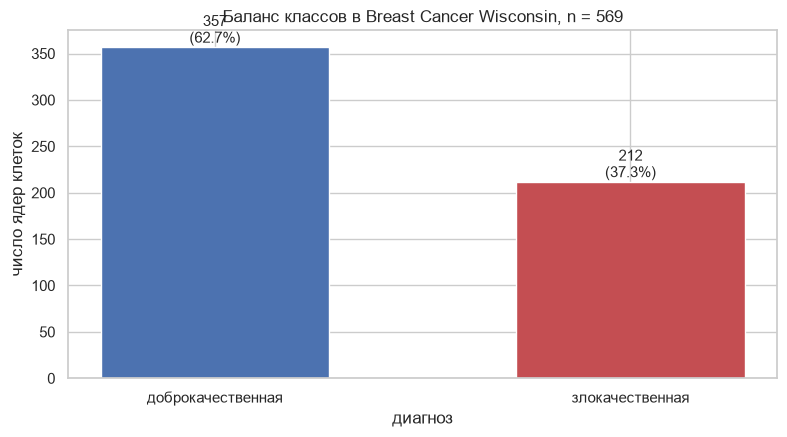

In [9]:
# Баланс классов - первое, что нужно увидеть. Именно он определяет, можно ли
# вообще доверять accuracy и какие метрики считать основными.
figure, axis = plt.subplots(figsize=(8, 4.5))
bar_colors = ["#4c72b0", "#c44e52"]
bars = axis.bar([CLASS_NAMES[value] for value in class_table.index],
                class_table["ядер"], color=bar_colors, width=0.55)
axis.bar_label(bars, labels=[f"{value}\n({share:.1%})"
                             for value, share in zip(class_table["ядер"], class_table["доля"])])
axis.set_ylabel("число ядер клеток")
axis.set_xlabel("диагноз")
axis.set_title(f"Баланс классов в Breast Cancer Wisconsin, n = {len(data)}")
figure.tight_layout()
plt.show()


## 2. Проверка и очистка

Проверяем датасет по четырём фронтам, которые и требует ТЗ:

1. **пропуски** (`NaN`, пустые поля);
2. **дубликаты** - и полные повторы строк, и повторы по набору признаков;
3. **физически невозможные значения** - нулевой радиус или отрицательная площадь;
4. **статистические выбросы** - правило «забора Тьюки».

Датасет из библиотеки приходит без пропусков и без дублей, поэтому ожидаем,
что часть проверок даст нули. Код всё равно написан полностью и выполняется:
по требованию к оформлению нельзя просто сказать «данные чистые», нужно это
показать.


In [10]:
# Пропуски - самая частая проблема в реальных таблицах: без них модель либо
# падает, либо молча обучается на «пустых» строках.
missing = data[FEATURE_COLUMNS + [TARGET]].isna().sum()
print(f"всего пропусков в таблице: {int(missing.sum())}")
print(f"строк хотя бы с одним пропуском: {int(data.isna().any(axis=1).sum())}")

# Проверка на нечисловые значения: если где-то вместо числа оказалась строка,
# это тот же пропуск, только записанный иначе, и isna() его не увидит.
non_numeric = 0
for column in FEATURE_COLUMNS:
    non_numeric += int((~pd.to_numeric(data[column], errors="coerce").notna()).sum())
print(f"нечисловых значений среди 30 признаков: {non_numeric}")


всего пропусков в таблице: 0
строк хотя бы с одним пропуском: 0
нечисловых значений среди 30 признаков: 0


In [11]:
# Стратегия на случай, если пропуски появятся: числовые признаки заполняем
# медианой - она устойчива к выбросам, в отличие от среднего, и не сдвигает
# распределение. Сейчас код ничего не меняет, потому что пропусков нет.
numeric_columns = data[FEATURE_COLUMNS].columns.tolist()
medians = data[numeric_columns].median()

clean = data.copy()
clean[numeric_columns] = clean[numeric_columns].fillna(medians)

print("пропусков до заполнения:", int(data[FEATURE_COLUMNS].isna().sum().sum()),
      "- после:", int(clean[FEATURE_COLUMNS].isna().sum().sum()))
print("медианы первых шести признаков:")
medians.head(6).round(3)


пропусков до заполнения: 0 - после: 0
медианы первых шести признаков:


mean radius          13.370
mean texture         18.840
mean perimeter       86.240
mean area           551.100
mean smoothness       0.096
mean compactness      0.093
dtype: float64

In [12]:
# Дубликаты: полный повтор строки означал бы двойной ввод данных, а повтор
# только по признакам - два разных ядра с неотличимыми измерениями.
full_duplicates = int(clean.duplicated().sum())
feature_duplicates = int(clean.duplicated(subset=FEATURE_COLUMNS).sum())

print(f"полных дубликатов строк: {full_duplicates}")
print(f"повторов по набору из 30 признаков: {feature_duplicates}")

# Более тонкая проверка, которой нет почти нигде: тот же набор признаков,
# округлённый до целых. Если такие повторы есть, датасет мог собираться
# из агрегатов с ограниченной точностью.
rounded_duplicates = int(clean[FEATURE_COLUMNS].round(0).duplicated().sum())
print(f"повторов после округления признаков до целых: {rounded_duplicates}")
print(f"строк после удаления полных дубликатов: {len(clean) - full_duplicates}")


полных дубликатов строк: 0
повторов по набору из 30 признаков: 0
повторов после округления признаков до целых: 0
строк после удаления полных дубликатов: 569


In [13]:
# Аномалии первого типа - значения вне физически возможных диапазонов.
# Размер ядра не может быть нулевым или отрицательным, площадь - отрицательной.
# Для измерений контура действуют те же ограничения: они вычисляются из
# координат точек и по определению неотрицательны.
PHYSICAL_LIMITS = {
    column: (0.0, None) for column in FEATURE_COLUMNS
}

def check_limits(frame):
    """Считает число значений, выпадающих из физически допустимого диапазона."""
    counts = {}
    for name, (low, high) in PHYSICAL_LIMITS.items():
        outside = frame[name] < low
        if high is not None:
            outside = outside | (frame[name] > high)
        counts[name] = int(outside.sum())
    return pd.Series(counts, name="нарушений диапазона")


limits_report = check_limits(clean)
implausible_rows = (limits_report > 0).any()

print(f"признаков под проверкой: {len(PHYSICAL_LIMITS)}")
print(f"нарушений всего: {int(limits_report.sum())}")
print(f"признаков с нарушениями: {int(implausible_rows.sum())}")
print()
print("нулевые значения - они допустимы физически, но стоит знать, сколько их:")
zeros = (clean[FEATURE_COLUMNS] == 0).sum()
print(zeros[zeros > 0].to_frame("нулей"))


признаков под проверкой: 30
нарушений всего: 0
признаков с нарушениями: 0

нулевые значения - они допустимы физически, но стоит знать, сколько их:
                      нулей
mean concavity           13
mean concave points      13
concavity error          13
concave points error     13
worst concavity          13
worst concave points     13


In [14]:
# Аномалии второго типа - статистические выбросы. Пользуемся «забором Тьюки»:
# всё, что дальше Q1 - 1.5*IQR или Q3 + 1.5*IQR, считается выбросом.
# Метод выбран потому, что не требует распределения и устойчив к форме данных.
def iqr_bounds(frame, factor=1.5):
    """Границы выбросов по межквартильному размаху: Q1 - f*IQR и Q3 + f*IQR."""
    lower_quartile = frame.quantile(0.25)
    upper_quartile = frame.quantile(0.75)
    interquartile_range = upper_quartile - lower_quartile
    return (lower_quartile - factor * interquartile_range,
            upper_quartile + factor * interquartile_range)


lower, upper = iqr_bounds(clean[FEATURE_COLUMNS])
outlier_mask = (clean[FEATURE_COLUMNS] < lower) | (clean[FEATURE_COLUMNS] > upper)
outlier_rows = outlier_mask.any(axis=1)

print(f"строк с хотя бы одним выбросом: {int(outlier_rows.sum())} из {len(clean)} "
      f"({outlier_rows.mean():.1%})")
print()
print("признаки, у которых выбросов больше всего:")
print(outlier_mask.sum().sort_values(ascending=False).head(8).to_frame("выбросов"))
print()
print("границы «забора Тьюки» для шести самых «выбросных» признаков:")
worst_features = outlier_mask.sum().sort_values(ascending=False).head(6).index
pd.DataFrame({"нижняя граница": lower[worst_features].round(3),
              "верхняя граница": upper[worst_features].round(3)})


строк с хотя бы одним выбросом: 171 из 569 (30.1%)

признаки, у которых выбросов больше всего:
                         выбросов
area error                     65
radius error                   38
perimeter error                38
worst area                     35
smoothness error               30
fractal dimension error        28
compactness error              28
symmetry error                 27

границы «забора Тьюки» для шести самых «выбросных» признаков:


,нижняя граница,верхняя граница
area error,-23.160,86.200
radius error,-0.137,0.849
perimeter error,-1.020,5.984
worst area,-337.750,1937.050
smoothness error,0.001,0.013
fractal dimension error,-0.001,0.008


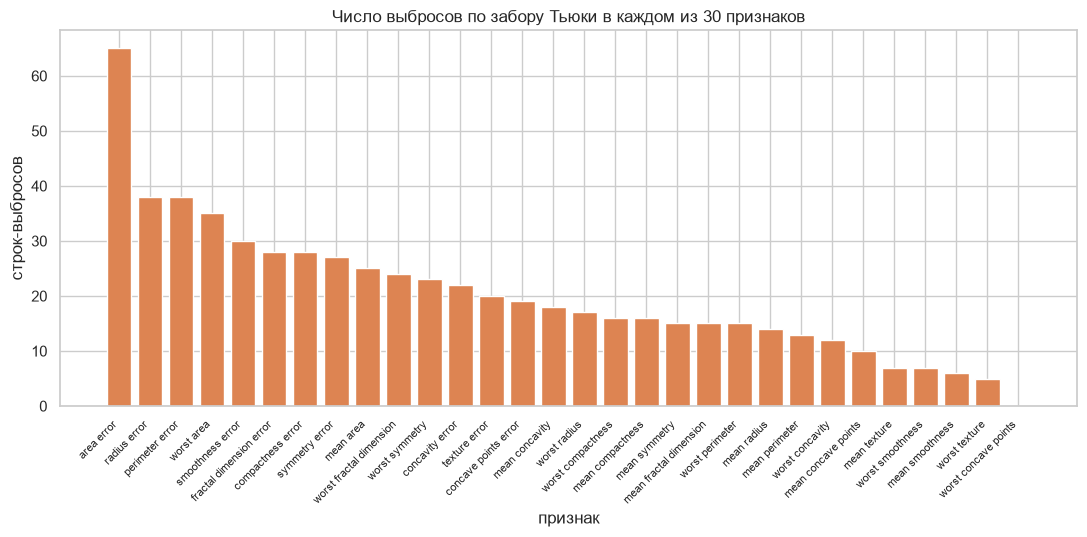

среднее число выбросов на один признак в блоке:
                выбросов
ошибки (error)      31.5
средние (mean)      13.9
худшие (worst)      15.4


In [15]:
# Выбросы по блокам: видно, что «error»-признаки ими гораздо богаче средних.
# Это ожидаемо - стандартное отклонение по маленькой выборке ядер само по себе
# тяжелее на хвосте, и путать это с ошибкой в данных не нужно.
figure, axis = plt.subplots(figsize=(11, 5.5))
bar_colors = [BLOCK_LABELS[block] for block in
              [feature_block(name) for name in outlier_mask.sum().sort_values(
                  ascending=False).index]]
axis.bar(range(len(outlier_mask.sum())), outlier_mask.sum().sort_values(ascending=False),
         color="#dd8452")
axis.set_xticks(range(len(outlier_mask.sum())))
axis.set_xticklabels(outlier_mask.sum().sort_values(ascending=False).index,
                     rotation=45, ha="right", fontsize=8)
axis.set_ylabel("строк-выбросов")
axis.set_xlabel("признак")
axis.set_title("Число выбросов по забору Тьюки в каждом из 30 признаков")
figure.tight_layout()
plt.show()

per_block = outlier_mask.sum().groupby([feature_block(name) for name in
                                        outlier_mask.columns]).mean()
print("среднее число выбросов на один признак в блоке:")
print(per_block.rename(index=BLOCK_LABELS).round(2).to_frame("выбросов"))


### Что делаем с выбросами

Выбросы здесь - это **не битые записи, а крайние случаи болезни**.
Крупное ядро с неровным контуром и длинными отростками вполне может оказаться
злокачественным, и именно такие ядра составляют малую, но важную часть
датасета. Удалять их нельзя: мы бы выбросили из обучения самые характерные
образцы болезни и заранее испортили модель.

Поэтому выбросы **оставляем**, но запоминаем их номера. В разборе ошибок мы
посмотрим, связаны ли ошибки модели именно с этими строками. Если бы среди них
оказались отрицательные площади или радиусы в сотни раз выше максимума, это были
бы уже ошибки записи - и тогда строки удаляются.


In [16]:
# Смотрим на самые экстремальные строки: убеждаемся, что это реальные ядра,
# а не опечатка при вводе. Смотрим на блок «mean», где величины читаются.
SUSPICIOUS_FEATURES = ["mean radius", "mean perimeter", "mean area", "mean concavity"]
extremes = clean.nlargest(3, "mean radius")[SUSPICIOUS_FEATURES + [TARGET, "target"]].copy()
extremes["диагноз"] = [CLASS_NAMES[value] for value in extremes[TARGET]]
extremes["target"] = extremes["target"].astype(int)

print("три самых крупных ядра в датасете:")
extremes.round(3)


три самых крупных ядра в датасете:


,mean radius,mean perimeter,mean area,mean concavity,label,target,диагноз
212,28.11,188.5,2499.0,0.320,1,0,злокачественная
461,27.42,186.9,2501.0,0.364,1,0,злокачественная
180,27.22,182.1,2250.0,0.287,1,0,злокачественная


In [17]:
# Итог очистки: строки не удалялись, данные не подменялись - проверено и
# признано пригодными.
print(f"строк было: {len(data)} - строк после очистки: {len(clean)}")
print(f"столбцов: {clean.shape[1]} - из них признаков: {len(numeric_columns)}, "
      f"исходная метка target и рабочая метка label - категориальных признаков: 0")
print(f"пропусков: {int(clean[FEATURE_COLUMNS].isna().sum().sum())} - "
      f"нечисловых значений: {non_numeric} - полных дубликатов: {full_duplicates}")
print(f"повторов по набору признаков: {feature_duplicates} "
      f"(после округления до целых: {rounded_duplicates})")
print(f"нарушений физического диапазона: {int(limits_report.sum())}")
print(f"выбросов-строк оставлено осознанно: {int(outlier_rows.sum())} ({outlier_rows.mean():.1%})")
print()
print("пропуски закрыты, ни одна строка не потеряна: "
      f"{len(clean)} из {len(data)}")
clean[SUSPICIOUS_FEATURES + [TARGET]].head()


строк было: 569 - строк после очистки: 569
столбцов: 32 - из них признаков: 30, исходная метка target и рабочая метка label - категориальных признаков: 0
пропусков: 0 - нечисловых значений: 0 - полных дубликатов: 0
повторов по набору признаков: 0 (после округления до целых: 0)
нарушений физического диапазона: 0
выбросов-строк оставлено осознанно: 171 (30.1%)

пропуски закрыты, ни одна строка не потеряна: 569 из 569


,mean radius,mean perimeter,mean area,mean concavity,label
0,17.99,122.80,1001.0,0.3001,1
1,20.57,132.90,1326.0,0.0869,1
2,19.69,130.00,1203.0,0.1974,1
3,11.42,77.58,386.1,0.2414,1
4,20.29,135.10,1297.0,0.1980,1


## 3. Разведочный анализ

Смотрим, с чем работаем:

* **распределения 30 признаков** - форма, скошенность, тяжёлые хвосты;
* **разделение классов** - какие признаки различают опухоли;
* **корреляции с целью** по всем 30 признакам с сортировкой;
* **корреляции между признаками** - источник мультиколлинеарности.


### Распределения числовых признаков

Все 30 признаков смотрят на одной сетке. Видно три разных типа распределений.

* Блок `mean` - распределения слегка скошены вправо, тяжёлых хвостов почти нет.
* Блок `error` - **сильно скошены вправо**: у большинства снимков ядра
  различаются мало, а у отдельных - очень сильно, поэтому среднее и разброс
  ведут себя по-разному.
* Блок `worst` - снова спокойные распределения, но сдвинутые вправо по
  сравнению с `mean`: «худшее» ядро по определению больше типичного.


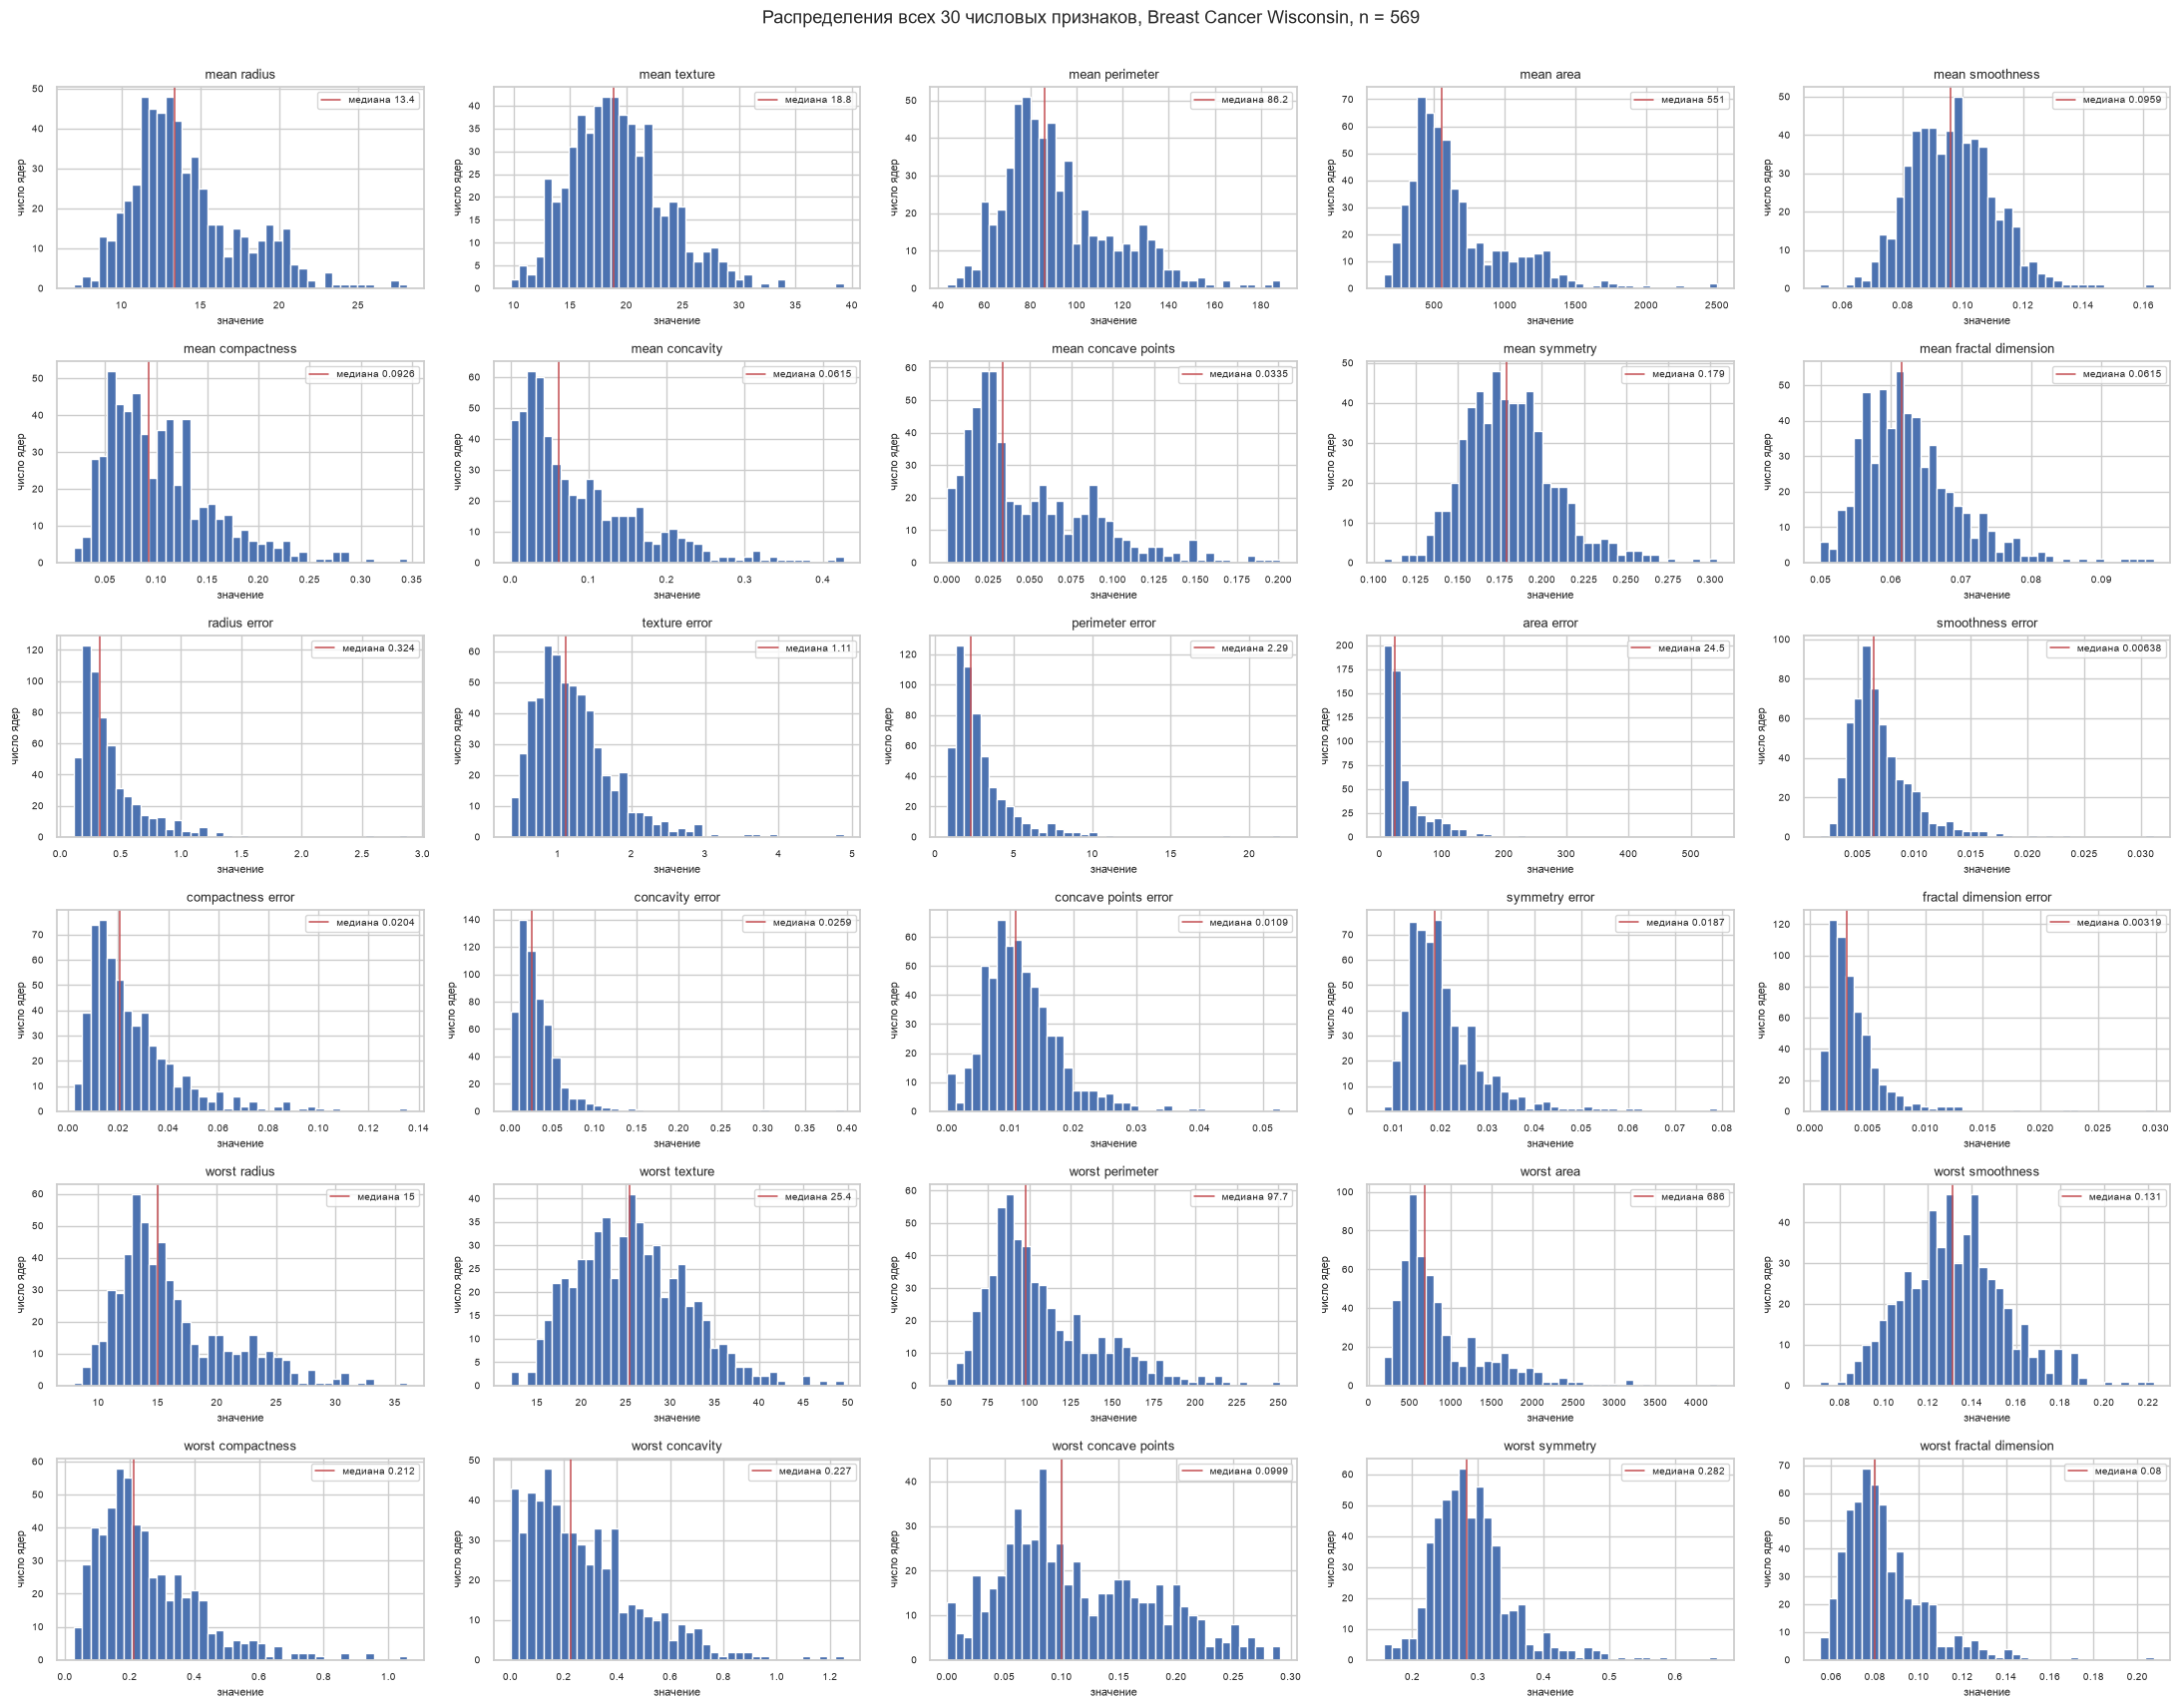

средняя скошенность по блокам (больше нуля - длинный правый хвост):
блок
ошибки (error)    3.05
средние (mean)    1.05
худшие (worst)    1.12
Name: скошенность, dtype: float64


In [18]:
# Смотрим все 30 признаков на одной сетке: так сразу видно, где
# распределение «нормальное», а где это тяжёлый правый хвост.
figure, axes = plt.subplots(6, 5, figsize=(22, 17))
axes = axes.ravel()

for axis, column in zip(axes, FEATURE_COLUMNS):
    values = clean[column]
    axis.hist(values, bins=40, color="#4c72b0", edgecolor="white")
    axis.axvline(values.median(), color="#c44e52", linewidth=1.1,
                 label=f"медиана {values.median():.3g}")
    axis.set_title(column, fontsize=9)
    axis.set_xlabel("значение", fontsize=8)
    axis.set_ylabel("число ядер", fontsize=8)
    axis.tick_params(labelsize=7)
    axis.legend(fontsize=7)

figure.suptitle("Распределения всех 30 числовых признаков, Breast Cancer Wisconsin, "
                f"n = {len(clean)}", y=1.005)
figure.tight_layout()
plt.show()

# Численное подтверждение того, что видно глазами: скошенность распределений.
skewness = pd.DataFrame({
    "скошенность": clean[FEATURE_COLUMNS].skew(),
    "блок": [feature_block(name) for name in FEATURE_COLUMNS],
})
print("средняя скошенность по блокам (больше нуля - длинный правый хвост):")
print(skewness.groupby("блок")["скошенность"].mean().rename(index=BLOCK_LABELS).round(2))


### Какие признаки различают два диагноза

Отдельный вопрос, ради которого датасет и выбран: **чем злокачественные ядра
отличаются от доброкачественных**. Смотрим четыре самых информативных признака
по ящикам с усами, разделённым по диагнозу.

Ожидание подтверждается: у злокачественных ядер заметно больше площадь и
вогнутость контура, а у доброкачественных распределения смещены влево и
сжаты. Именно эти признаки потом окажутся сильнейшими в модели.


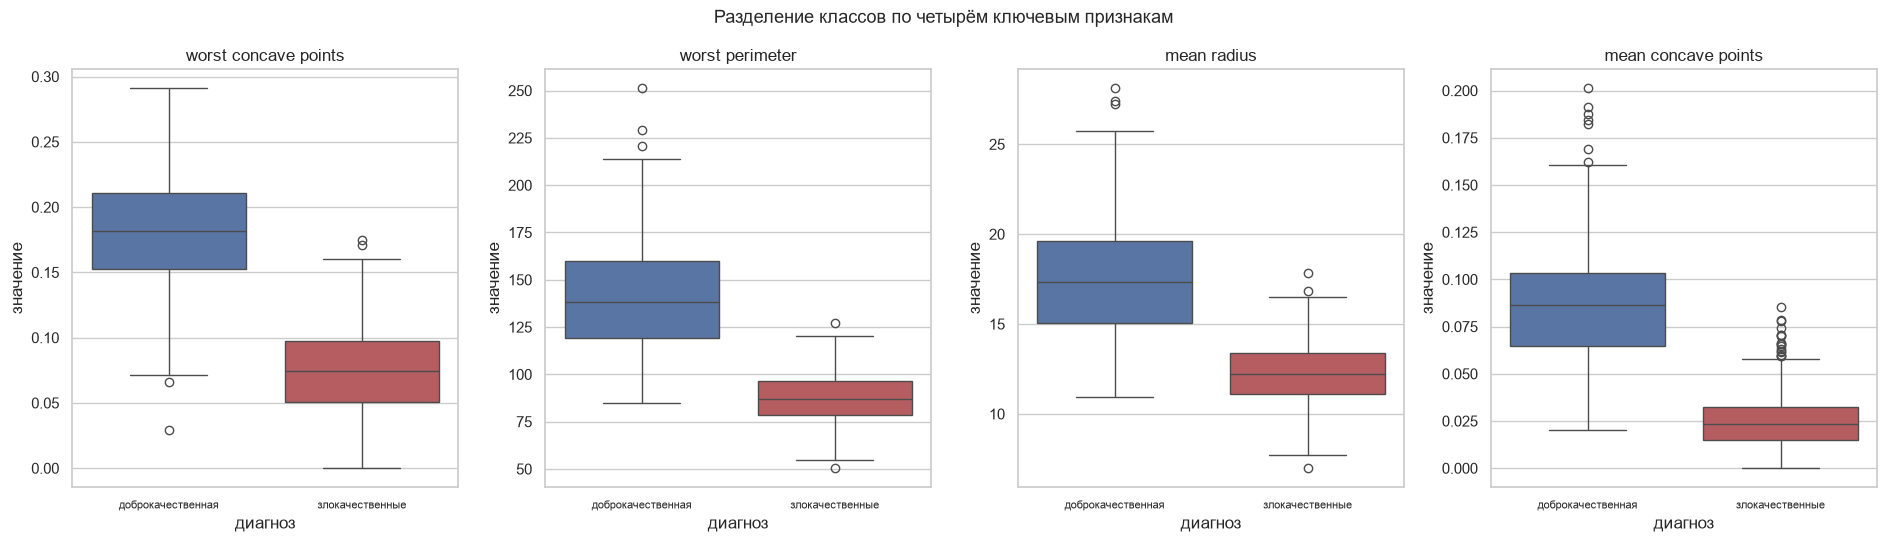

медиана признака по диагнозам:


,доброкачественная,злокачественная
worst concave points,0.07431,0.18200
worst perimeter,86.92000,138.00000
mean radius,12.20000,17.32500
mean concave points,0.02344,0.08628


In [19]:
# Ящики с усами по диагнозу. Красным отмечена медиана злокачественных -
# она почти везде правее, то есть признак работает в ожидаемую сторону.
figure, axes = plt.subplots(1, 4, figsize=(19, 5.5))

for axis, column in zip(axes, ["worst concave points", "worst perimeter",
                                "mean radius", "mean concave points"]):
    sns.boxplot(data=clean, x="target", y=column, hue="target",
                order=[0, 1], palette=["#4c72b0", "#c44e52"],
                legend=False, ax=axis)
    axis.set_title(column)
    axis.set_xlabel("диагноз")
    axis.set_ylabel("значение")
    # Подписи задаём вместе с положением меток: один вызов set_xticks вместо
    # set_xticklabels, который без фиксированных меток вызывает предупреждение.
    axis.set_xticks([0, 1], labels=["доброкачественная", "злокачественные"],
                    fontsize=8)

figure.suptitle("Разделение классов по четырём ключевым признакам")
figure.tight_layout()
plt.show()

# Та же мысль в числах: медиана по группам и во сколько раз они отличаются.
print("медиана признака по диагнозам:")
medians_by_class = (clean.groupby(TARGET)[["worst concave points", "worst perimeter",
                                          "mean radius", "mean concave points"]].median())
medians_by_class.index = [CLASS_NAMES[value] for value in medians_by_class.index]
medians_by_class.T


### Корреляции

Полная матрица корреляций на 30 признаках нечитаема: это 900 ячеек, из которых
большинство - почти нули. Поэтому делаем два графика, и каждый отвечает на
свой вопрос.

**Первый вопрос - что связано с диагнозом.** Корреляция всех 30 признаков с
целевой переменной, отсортированная по модулю. Здесь видно главное: работают
размеры и форма ядра, а почти не работают текстура, симметрия и
«фрактальная размерность». Ровно половина из 30 признаков даёт модуль корреляции
выше 0.5, и почти все они сидят в блоках `mean` и `worst`; пять признаков дают
модуль меньше 0.1 и для этой задачи бесполезны.

**Второй вопрос - что связано между собой.** Матрица корреляций между самими
30 признаками, упорядоченная по блокам. Она показывает структуру, которой не
видно по отдельным числам: **средний модуль корреляции внутри одного блока
(0.46) выше, чем между блоками (0.37), а все самые сильные пары - свыше
0.96 - лежат внутри блоков**.


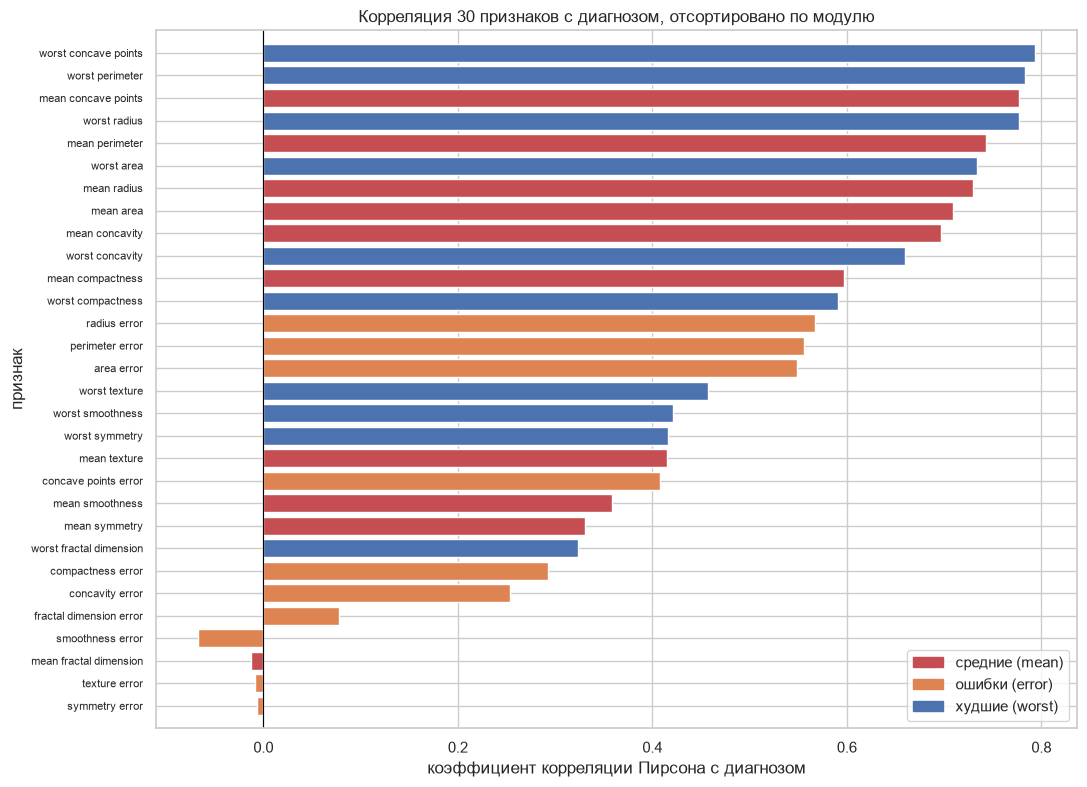

признаков с |r| > 0.5: 15 из 30
признаков с |r| < 0.1 (бесполезных): 5

сильнейшие и слабейшие связи:


,r с диагнозом,блок
worst concave points,0.794,worst
worst perimeter,0.783,worst
mean concave points,0.777,mean
worst radius,0.776,worst
mean perimeter,0.743,mean
worst area,0.734,worst
mean radius,0.730,mean
mean area,0.709,mean
concavity error,0.254,error
fractal dimension error,0.078,error


In [20]:
# Корреляция Пирсона между каждым признаком и бинарной диагностикой.
# Она показывает силу линейной связи, но не знак диагноза: положительная
# корреляция означает "больше значения - вероятнее злокачественность".
target_correlation = clean[FEATURE_COLUMNS].corrwith(clean[TARGET]).sort_values(
    key=abs, ascending=False)
target_correlation_frame = pd.DataFrame({
    "корреляция с диагнозом": target_correlation,
    "блок": [feature_block(name) for name in target_correlation.index],
})

figure, axis = plt.subplots(figsize=(11, 8))
position = np.arange(len(target_correlation))
colors = {"mean": "#c44e52", "error": "#dd8452", "worst": "#4c72b0"}
axis.barh(position, target_correlation_frame["корреляция с диагнозом"],
           color=[colors[block] for block in target_correlation_frame["блок"]])
axis.set_yticks(position)
axis.set_yticklabels(target_correlation_frame.index, fontsize=8)
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel("коэффициент корреляции Пирсона с диагнозом")
axis.set_ylabel("признак")
axis.set_title("Корреляция 30 признаков с диагнозом, отсортировано по модулю")

handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colors.values()]
axis.legend(handles, [BLOCK_LABELS[block] for block in colors], loc="lower right")
axis.set_ylim(-1, len(position))
axis.invert_yaxis()
figure.tight_layout()
plt.show()

print(f"признаков с |r| > 0.5: {int((target_correlation.abs() > 0.5).sum())} из 30")
print(f"признаков с |r| < 0.1 (бесполезных): {int((target_correlation.abs() < 0.1).sum())}")
print()
print("сильнейшие и слабейшие связи:")
display(pd.concat([target_correlation_frame.head(8), target_correlation_frame.tail(6)]
                  ).rename(columns={"корреляция с диагнозом": "r с диагнозом"}).round(3))


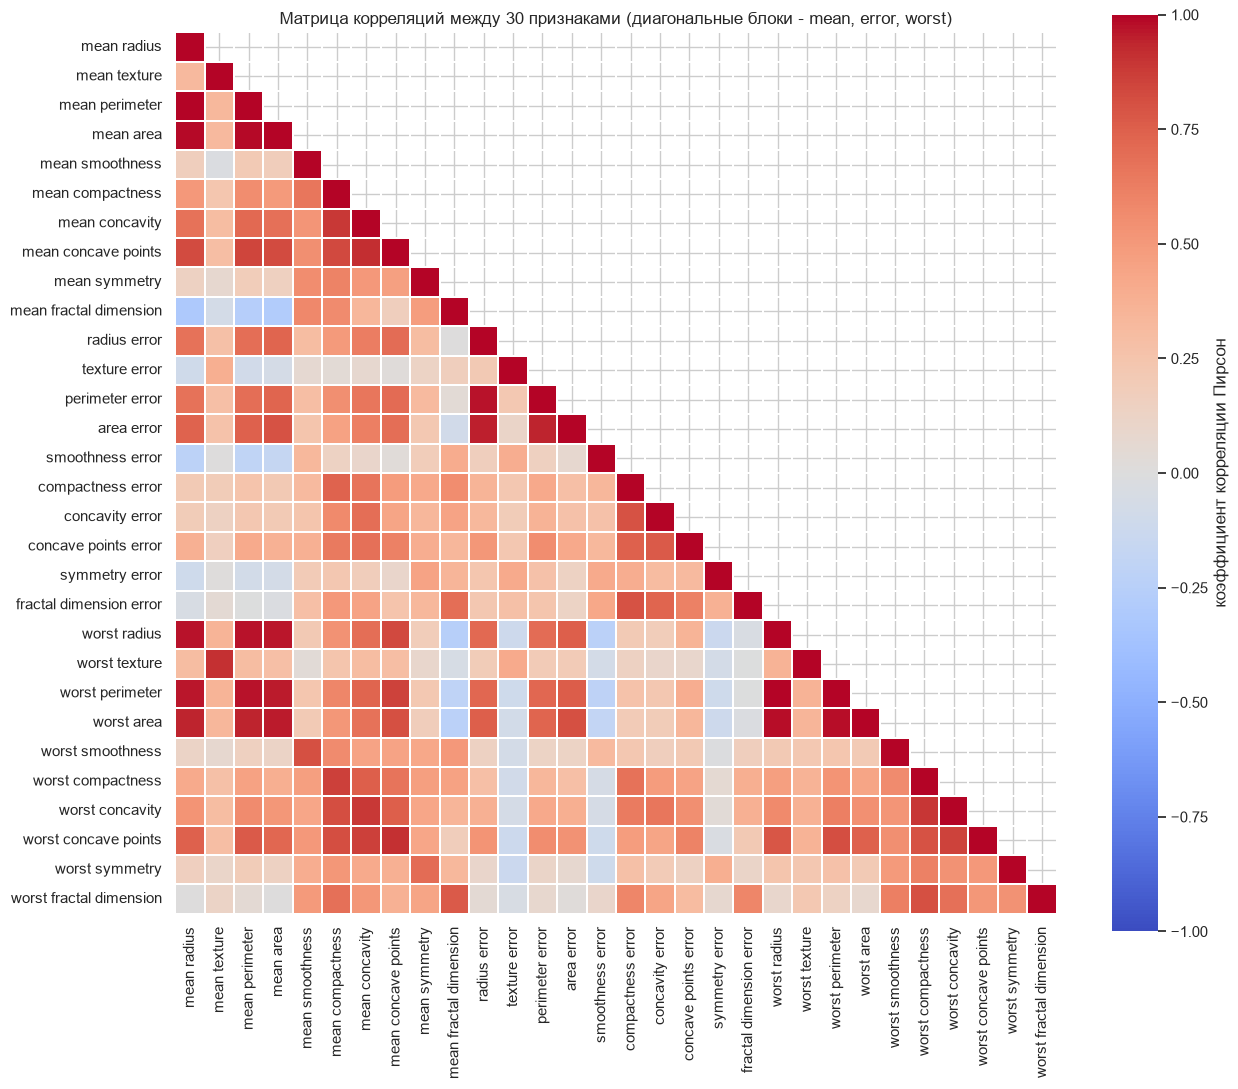

десять самых связанных пар признаков:
                                    |r|
признак 1       признак 2              
mean radius     mean perimeter   0.9979
worst radius    worst perimeter  0.9937
mean radius     mean area        0.9874
mean perimeter  mean area        0.9865
worst radius    worst area       0.9840
worst perimeter worst area       0.9776
radius error    perimeter error  0.9728
mean perimeter  worst perimeter  0.9704
mean radius     worst radius     0.9695
mean perimeter  worst radius     0.9695


In [21]:
# Матрица корреляций между признаками. Верхний треугольник маскируем: он
# симметричен нижнему и несёт ровно ту же информацию, а подписи в 465 ячейках
# превратили бы график в кашу. Порядок признаков оставляем исходным - в нём
# блоки mean, error и worst уже идут подряд, и структура видна цветом.
correlation = clean[FEATURE_COLUMNS].corr()
mask = np.triu(np.ones(correlation.shape, dtype=bool), k=1)

figure, axis = plt.subplots(figsize=(13, 11))
sns.heatmap(correlation, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=0.2,
            cbar_kws={"label": "коэффициент корреляции Пирсон"}, ax=axis)
axis.set_title("Матрица корреляций между 30 признаками (диагональные блоки - mean, error, worst)")
figure.tight_layout()
plt.show()

# Тот же вопрос в числах: какие пары признаков дублируют друг друга сильнее всего.
pairwise = correlation.abs().where(
    np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
pairwise.index = pd.MultiIndex.from_tuples(pairwise.index,
                                           names=["признак 1", "признак 2"])
print("десять самых связанных пар признаков:")
print(pairwise.sort_values(ascending=False).head(10).round(4).to_frame("|r|"))


In [22]:
# Тот же ракурс, но по блокам: усредняем модуль корреляции внутри и между
# блоками. Так видно главный вывод раздела: внутри блока признаки почти
# дублируют друг друга, между блоками - гораздо меньше.
block_of = {name: feature_block(name) for name in FEATURE_COLUMNS}
block_membership = pd.Series(block_of, name="блок")

inside_mean, outside_mean = [], []
for first in FEATURE_COLUMNS:
    for second in FEATURE_COLUMNS:
        if first >= second:
            continue
        value = abs(correlation.loc[first, second])
        if block_of[first] == block_of[second]:
            inside_mean.append(value)
        else:
            outside_mean.append(value)

print(f"средний |r| внутри одного блока: {np.mean(inside_mean):.3f} "
      f"(максимум {np.max(inside_mean):.3f})")
print(f"средний |r| между разными блоками: {np.mean(outside_mean):.3f} "
      f"(максимум {np.max(outside_mean):.3f})")
print()
print(f"пар с |r| > 0.9: {int((pairwise > 0.9).sum())}")
print(f"пар с |r| > 0.95: {int((pairwise > 0.95).sum())}")
print(f"максимальный |r| между признаками: {float(pairwise.max()):.4f}")
print()
print("вывод: признаки внутри блока измеряют почти одно и то же разными")
print("способами. Дальше в разделе про коэффициенты мы увидим, к чему это приводит.")

# Таблица «структура признаков» - один взгляд на весь набор из 30.
structure_table = pd.DataFrame({
    "блок": block_membership,
    "измерение": [measurement_name(name) for name in FEATURE_COLUMNS],
    "r с диагнозом": target_correlation_frame["корреляция с диагнозом"].reindex(FEATURE_COLUMNS),
}).sort_values("r с диагнозом", key=abs, ascending=False)
structure_table.head(12).round(3)


средний |r| внутри одного блока: 0.460 (максимум 0.998)
средний |r| между разными блоками: 0.366 (максимум 0.970)

пар с |r| > 0.9: 21
пар с |r| > 0.95: 15
максимальный |r| между признаками: 0.9979

вывод: признаки внутри блока измеряют почти одно и то же разными
способами. Дальше в разделе про коэффициенты мы увидим, к чему это приводит.


,блок,измерение,r с диагнозом
worst concave points,worst,concave points,0.794
worst perimeter,worst,perimeter,0.783
mean concave points,mean,concave points,0.777
worst radius,worst,radius,0.776
mean perimeter,mean,perimeter,0.743
worst area,worst,area,0.734
mean radius,mean,radius,0.730
mean area,mean,area,0.709
mean concavity,mean,concavity,0.696
worst concavity,worst,concavity,0.660


### Мультиколлинеарность: главная проблема этого датасета

Корреляции выше показали, что внутри каждого блока признаки почти
дублируют друг друга. Разберём это на конкретной тройке.

`mean radius`, `mean perimeter` и `mean area` - это **размер, периметр и
площадь одного и того же ядра**. Физически они связаны почти формулой:
у круга периметр пропорционален радиусу, а площадь - его квадрату.
Корреляция между ними превышает 0.98, то есть это не три независимых
признака, а по сути один, записанный трижды.

Обычно такое называют **мультиколлинеарностью**, и у неё есть конкретное
последствие: **коэффициенты перестают быть устойчивыми**. Если два признака
несут одну и ту же информацию, метод оптимизации волен распределить их вклад
как угодно - и при малейшем изменении данных распределит иначе. Прогнозы от
этого почти не меняются, а коэффициенты - меняются радикально.

Проверим это инструментом, который для этого и существует: **VIF**
(variance inflation factor, коэффициент инфляции дисперсии). Он показывает,
во сколько раз вырастает дисперсия коэффициента данного признака из-за его
связи с остальными. Значение выше 10 считается критическим.


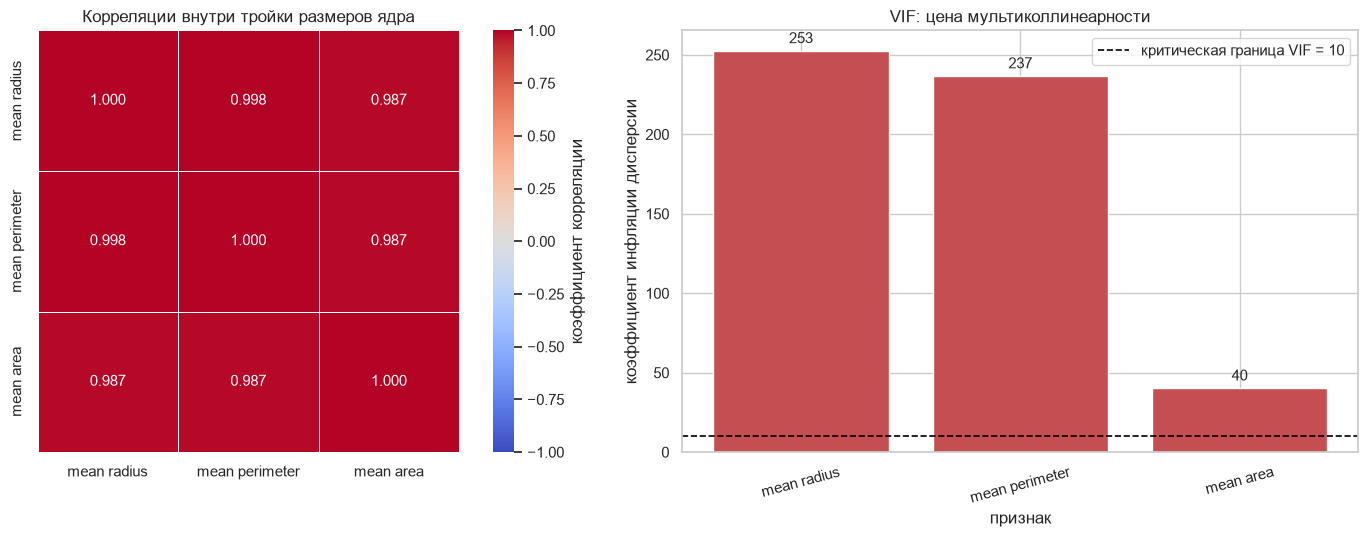

корреляции внутри тройки:
                mean radius  mean perimeter  mean area
mean radius          1.0000          0.9979     0.9874
mean perimeter       0.9979          1.0000     0.9865
mean area            0.9874          0.9865     1.0000

коэффициент инфляции дисперсии:
                  VIF
mean radius     252.7
mean perimeter  236.9
mean area        40.4
критическая граница VIF = 10, а здесь 253 - превышение в 25 раз
считаем VIF только для этой тройки: на всех 30 признаках матрица 30x30
почти вырождена и её обращение даёт числовой шум, а не содержательные числа.
вывод: эти признаки не добавляют модели информации, но ломают её коэффициенты.


In [23]:
# Коэффициент инфляции дисперсии для тройки размеров.
# VIF считается как диагональная элемент обратной матрицы корреляций.
TRIO = ["mean radius", "mean perimeter", "mean area"]

def vif_values(frame):
    """VIF каждого столбца: во сколько раз вырастает разброс его коэффициента."""
    correlation_matrix = np.corrcoef(frame.to_numpy().T)
    return pd.Series(np.diag(np.linalg.inv(correlation_matrix)), index=frame.columns)


vif_trio = vif_values(clean[TRIO])

figure, (axis_left, axis_right) = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(clean[TRIO].corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "коэффициент корреляции"}, ax=axis_left)
axis_left.set_title("Корреляции внутри тройки размеров ядра")

bars = axis_right.bar(vif_trio.index, vif_trio.values, color="#c44e52")
axis_right.bar_label(bars, fmt="%.0f", padding=3)
axis_right.axhline(10, color="black", linestyle="--", linewidth=1.2,
                   label="критическая граница VIF = 10")
axis_right.set_ylabel("коэффициент инфляции дисперсии")
axis_right.set_xlabel("признак")
axis_right.set_title("VIF: цена мультиколлинеарности")
axis_right.tick_params(axis="x", rotation=15)
axis_right.legend()

figure.tight_layout()
plt.show()

print("корреляции внутри тройки:")
print(clean[TRIO].corr().round(4))
print()
print(f"коэффициент инфляции дисперсии:")
print(vif_trio.round(1).to_frame("VIF"))
print(f"критическая граница VIF = 10, а здесь {vif_trio.max():.0f} - превышение в "
      f"{vif_trio.max() / 10:.0f} раз")
print(f"считаем VIF только для этой тройки: на всех 30 признаках матрица 30x30")
print("почти вырождена и её обращение даёт числовой шум, а не содержательные числа.")
print("вывод: эти признаки не добавляют модели информации, но ломают её коэффициенты.")


## 4. Подготовка данных

Два шага, каждый из которых меняет только обучающую выборку:

1. **Разделение** на train / validation / test с фиксированным `random_state`.
2. **Масштабирование** числовых признаков. Среднее и разброс считаются
   **только на train** - если посчитать их на всей таблице, в модель бы попала
   информация о тесте, и оценка качества оказалась бы завышенной.

Кодировать здесь нечего: все 30 признаков числовые, категорий нет. Это
удобно, но не повод проверять - проверка типов и состава столбцов остаётся в
работе.


### Разделение на train / validation / test со стратификацией

Делим выборку на три части:

* **train** (60 %) - обучение весов;
* **validation** (20 %) - подбор порога вероятности;
* **test** (20 %) - единственная честная оценка, к которой модель
  прикасается один раз в самом конце.

Ключевой момент - `stratify=y`. Он требует, чтобы доля злокачественных ядер
в каждой части **совпала с исходной**. Без этого при случайном разбиении часть
выборки может отклониться по балансу классов, и метрики скачут от запуска к
запуску: а в тестовой части всего 114 строк и 42 злокачественных ядра, так
что одна ошибка меняет recall на 2.4 процентных пункта, а accuracy - всего на
0.9. Стратификация делает оценку воспроизводимой.

`random_state=SEED` фиксирует само разбиение: без него каждый запуск ноутбука
давал бы другие цифры.


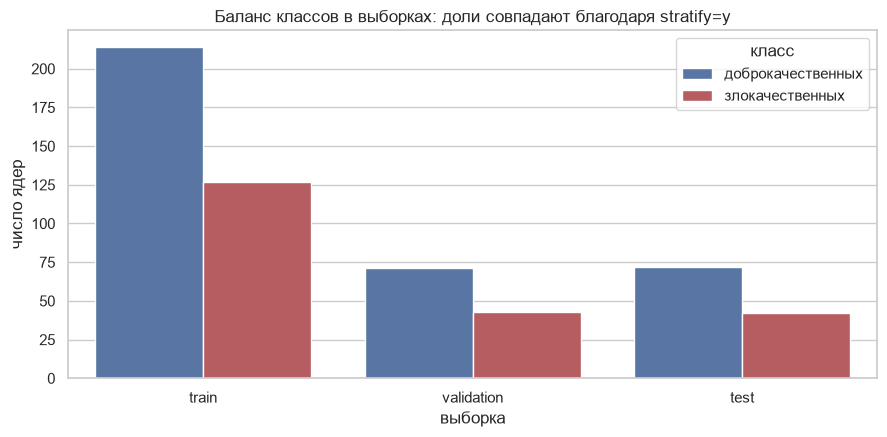

доля злокачественных в исходных данных: 0.373
train: 341 · validation: 114 · test: 114
во всех трёх выборках доля злокачественных одинакова - разбиение стратифицировано корректно.


,выборка,объектов,злокачественных,доброкачественных,доля_злокачественных
0,train,341,127,214,0.372
1,validation,114,43,71,0.377
2,test,114,42,72,0.368


In [24]:
X = clean.drop(columns=["target", TARGET])
y = clean[TARGET]

# Двумя шагами: сначала отделяем 40 % под валидацию и тест, затем делим их пополам.
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED, shuffle=True)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED, shuffle=True)

split_report = pd.DataFrame({
    "выборка": ["train", "validation", "test"],
    "объектов": [len(X_train), len(X_val), len(X_test)],
    "злокачественных": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "доброкачественных": [int((y_train == 0).sum()), int((y_val == 0).sum()),
                          int((y_test == 0).sum())],
})
split_report["доля_злокачественных"] = (split_report["злокачественных"]
                                         / split_report["объектов"]).round(3)

figure, axis = plt.subplots(figsize=(9, 4.5))
split_melted = split_report.melt(id_vars="выборка",
                                 value_vars=["доброкачественных", "злокачественных"],
                                 var_name="класс", value_name="ядер")
sns.barplot(data=split_melted, x="выборка", y="ядер", hue="класс", ax=axis,
            palette=["#4c72b0", "#c44e52"])
axis.set_title("Баланс классов в выборках: доли совпадают благодаря stratify=y")
axis.set_xlabel("выборка")
axis.set_ylabel("число ядер")
figure.tight_layout()
plt.show()

print(f"доля злокачественных в исходных данных: {y.mean():.3f}")
print(f"train: {len(X_train)} · validation: {len(X_val)} · test: {len(X_test)}")
print("во всех трёх выборках доля злокачественных одинакова - "
      "разбиение стратифицировано корректно.")
display(split_report)


### Зачем здесь масштабирование

В этом датасете разброс признаков различается на **пять порядков**:

* `mean area` - площадь в квадратных десятых долях миллиметра, среднее
  около 654, стандартное отклонение около 352;
* `mean smoothness` - доля от 0.05 до 0.16, стандартное отклонение около 0.014;
* `area error` - стандартное отклонение около 40 при среднем 72.

Логистическая регрессия оптимизируется градиентным спуском, и если один
признак в тысячу раз крупнее другого, его градиент забивает остальные: модель
сходится медленно и неустойчиво, а при сильной мультиколлинеарности, которая
в этом датасете есть, - ещё и плохо обусловлена.

`StandardScaler` приводит каждый признак к нулевому среднему и единичному
разбросу. **Параметры scaler считаются только по train** и затем применяются
к валидации и тесту - иначе в модель просочилась бы информация из будущего, и
оценка оказалась бы завышена.


максимальный разброс признака: 546.2
минимальный разброс признака: 0.0027
отношение максимума к минимуму: 204075 раз


,разброс до,разброс после,во сколько раз различались
признак,,,
worst area,546.2296,545.4281,204075.0
mean area,344.6126,344.1069,128749.0
area error,44.3810,44.3158,16581.0
worst perimeter,32.6521,32.6042,12199.0
mean perimeter,23.9601,23.9249,8952.0
worst texture,6.1617,6.1526,2302.0


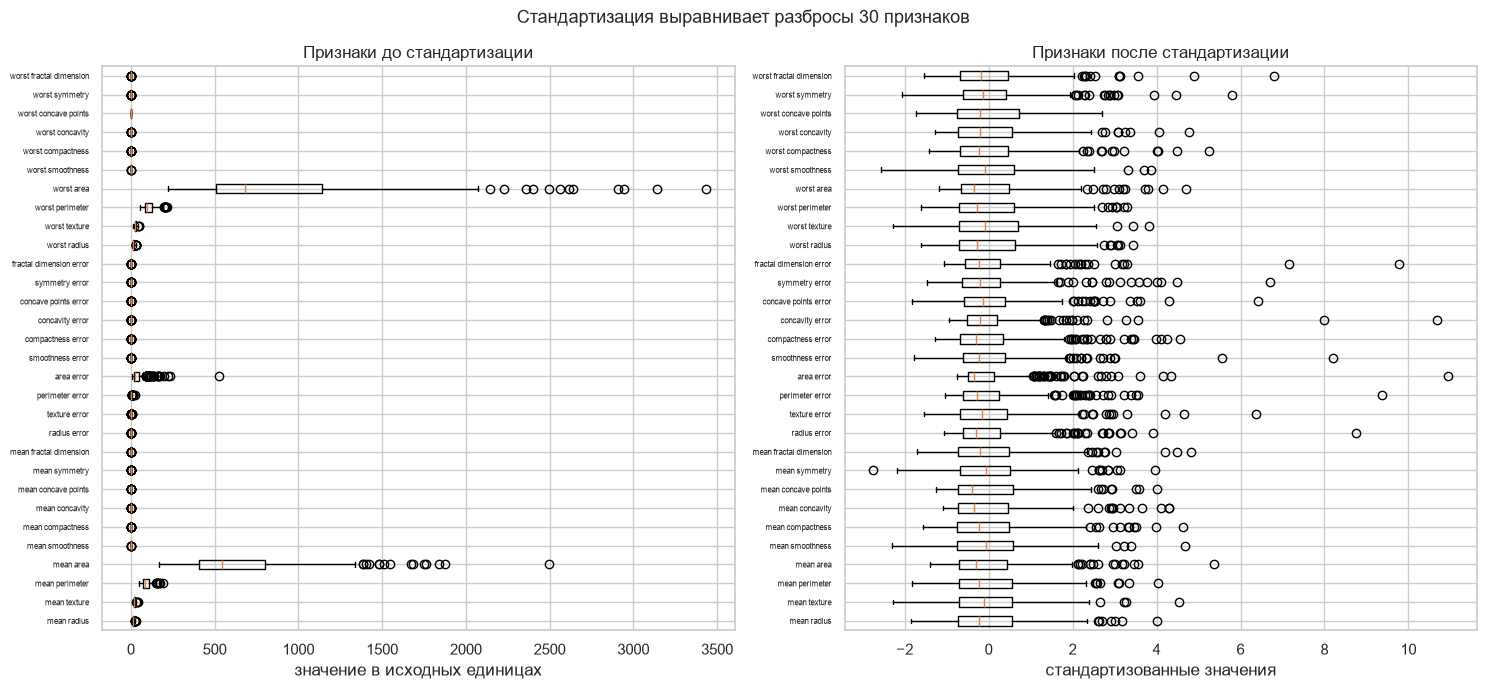

средние после fit на train (максимум от нуля): 1.29e-15
разбросы после fit на train (минимум и максимум): 1.000 и 1.000


In [25]:
# Показать масштаб «как есть»: без этого абзаца стандартизация выглядит
# формальностью, а разница в разбросе здесь пять порядков.
scaler_preview = StandardScaler().fit(X_train)
scaled_train_preview = scaler_preview.transform(X_train)

scale_table = pd.DataFrame({
    "разброс до": X_train.std().sort_values(ascending=False),
    "разброс после": pd.Series(scaler_preview.scale_, index=X_train.columns).sort_values(
        ascending=False),
}).rename_axis("признак")
scale_table["во сколько раз различались"] = (
    scale_table["разброс до"] / scale_table["разброс до"].iloc[-1]).round(0)

print(f"максимальный разброс признака: {X_train.std().max():.1f}")
print(f"минимальный разброс признака: {X_train.std().min():.4f}")
print(f"отношение максимума к минимуму: {X_train.std().max() / X_train.std().min():.0f} раз")
display(scale_table.head(6).round(4))

figure, (axis_before, axis_after) = plt.subplots(1, 2, figsize=(15, 7))

axis_before.boxplot([X_train[column].to_numpy() for column in X_train.columns],
                    orientation="horizontal")
axis_before.set_yticks(range(1, len(X_train.columns) + 1))
axis_before.set_yticklabels(X_train.columns, fontsize=6)
axis_before.set_title("Признаки до стандартизации")
axis_before.set_xlabel("значение в исходных единицах")

axis_after.boxplot([scaled_train_preview[:, index]
                    for index in range(scaled_train_preview.shape[1])],
                   orientation="horizontal")
axis_after.set_yticks(range(1, len(X_train.columns) + 1))
axis_after.set_yticklabels(X_train.columns, fontsize=6)
axis_after.set_title("Признаки после стандартизации")
axis_after.set_xlabel("стандартизованные значения")

figure.suptitle("Стандартизация выравнивает разбросы 30 признаков")
figure.tight_layout()
plt.show()

# Проверяем главное свойство: после fit среднее 0, разброс 1 - по ВСЕМ выборкам.
print(f"средние после fit на train (максимум от нуля): "
      f"{np.abs(scaled_train_preview.mean(axis=0)).max():.2e}")
print(f"разбросы после fit на train (минимум и максимум): "
      f"{scaled_train_preview.std(axis=0).min():.3f} и "
      f"{scaled_train_preview.std(axis=0).max():.3f}")


In [26]:
# Стандартизация и сама модель объединены в Pipeline. Это не стилистика:
# пайплайн гарантирует, что scaler обучается на тех же данных, что и модель,
# и что при любом переобучении порядок операций не нарушится.
model = Pipeline([
    ("scaler", StandardScaler()),                      # параметры берутся только из train
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
display(model)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_gl

## 5. Модель

### Уравнение логистической регрессии

Модель оценивает вероятность злокачественности через сигмоиду:

$$P(y=1 \mid x) = \sigma(w^\top x + b) = \frac{1}{1 + e^{-(w^\top x + b)}}$$

Логарифм отношения шансов линеен по признакам:

$$\ln\frac{P(y=1)}{P(y=0)} = w_0 + w_1 x_1 + \dots + w_{30} x_{30}$$

Коэффициенты находятся минимизацией логарифмической потери:

$$-\sum_i \left[ y_i \ln p_i + (1 - y_i) \ln(1 - p_i) \right]$$

Отсюда два практических следствия:

* коэффициенты **читаемы** - это не «черный ящик», как у леса деревьев:
  знак коэффициента прямо говорит, повышает или понижает вероятность;
* модель выдаёт не метку, а **вероятность**, а значит, порог принятия
  решения можно выбирать отдельно от обучения.


## 6. Обучение

### Функция обучения

Тестовая выборка в функцию не передаётся намеренно: так правило «модель не
видит тест до финальной оценки» закреплено в коде, а не только в тексте.


In [27]:
def train_logistic_regression(X_train, y_train):
    """Обучает пайплайн «стандартизация + логистическая регрессия».

    Тестовую выборка функция не принимает: все параметры, включая
    масштаб scaler, учатся только на train.
    """
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ])
    pipeline.fit(X_train, y_train)
    return pipeline


# Обучаем на train. Validation и test в этот момент не участвуют.
model = train_logistic_regression(X_train, y_train)
print("модель обучена на train, объектов:", len(X_train))
print("свободный член:", round(float(model.named_steps["clf"].intercept_[0]), 4))
print(f"число итераций оптимизации: {int(np.max(model.named_steps['clf'].n_iter_))} "
      f"из 1000 допустимых")
print(f"сходимость достигнута: {bool(np.max(model.named_steps['clf'].n_iter_) < 1000)}")


модель обучена на train, объектов: 341
свободный член: -0.4736
число итераций оптимизации: 19 из 1000 допустимых
сходимость достигнута: True


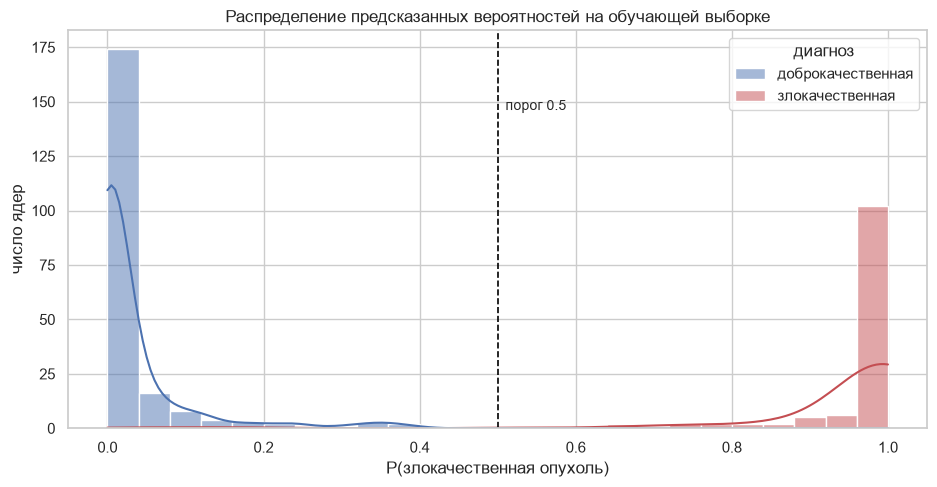

средняя вероятность для злокачественных:  0.948
средняя вероятность для доброкачественных: 0.031
доля злокачественных с вероятностью выше 0.5: 0.976
доля доброкачественных с вероятностью выше 0.5: 0.000
облака почти не перекрываются, но не настолько, что разделяются одним
порогом идеально - с этим предстоит разбираться в разделе оценки.


In [28]:
# Смотрим, как распределены предсказанные вероятности: классы должны быть
# разведены, но не идеально - идеальных классификаторов в медицине не бывает.
train_probabilities = model.predict_proba(X_train)[:, 1]

probability_frame = pd.DataFrame({
    "вероятность злокачественности": train_probabilities,
    "диагноз": [CLASS_NAMES[value] for value in y_train],
})

figure, axis = plt.subplots(figsize=(9.5, 5))
sns.histplot(data=probability_frame, x="вероятность злокачественности", hue="диагноз",
             hue_order=["доброкачественная", "злокачественная"],
             bins=25, kde=True, ax=axis, palette=["#4c72b0", "#c44e52"])
axis.axvline(0.5, linestyle="--", color="black", linewidth=1.2)
axis.text(0.51, axis.get_ylim()[1] * 0.8, "порог 0.5", fontsize=10)
axis.set_xlabel("P(злокачественная опухоль)")
axis.set_ylabel("число ядер")
axis.set_title("Распределение предсказанных вероятностей на обучающей выборке")
figure.tight_layout()
plt.show()

print(f"средняя вероятность для злокачественных:  {train_probabilities[y_train == 1].mean():.3f}")
print(f"средняя вероятность для доброкачественных: {train_probabilities[y_train == 0].mean():.3f}")
print(f"доля злокачественных с вероятностью выше 0.5: "
      f"{(train_probabilities[y_train == 1] > 0.5).mean():.3f}")
print(f"доля доброкачественных с вероятностью выше 0.5: "
      f"{(train_probabilities[y_train == 0] > 0.5).mean():.3f}")
print("облака почти не перекрываются, но не настолько, что разделяются одним")
print("порогом идеально - с этим предстоит разбираться в разделе оценки.")


,выборка,accuracy,разрыв с train
0,train,0.9912,0.0000
1,validation,0.9737,-0.0175


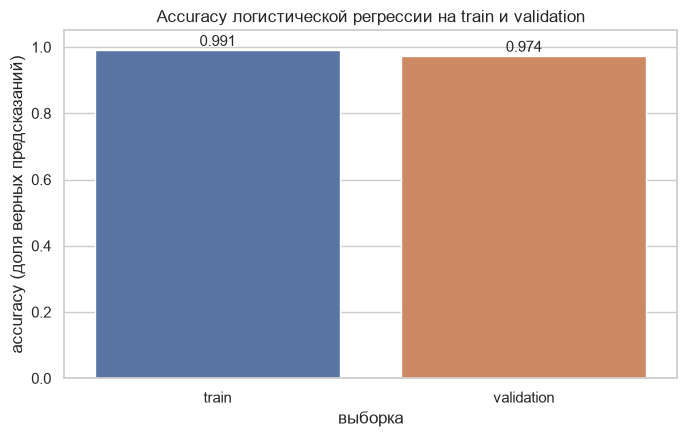

разрыв train - validation: -0.0175
разрыв мал, переобучения нет - линейная модель не способна запомнить
341 обучающих примеров так, чтобы провалиться на новых.


In [29]:
# Сравниваем качество на двух выборках, не обучаясь на них. Большой разрыв
# означал бы переобучение: модель запомнила обучающие примеры вместо того,
# чтобы выучить закономерность.
score_table = pd.DataFrame({
    "выборка": ["train", "validation"],
    "accuracy": [model.score(X_train, y_train), model.score(X_val, y_val)],
})
score_table["разрыв с train"] = score_table["accuracy"] - score_table["accuracy"].iloc[0]
display(score_table.round(4))

figure, axis = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=score_table, x="выборка", y="accuracy", hue="выборка",
            palette={"train": "#4c72b0", "validation": "#dd8452"}, legend=False, ax=axis)
axis.set_ylim(0, 1.05)
axis.set_title("Accuracy логистической регрессии на train и validation")
axis.set_xlabel("выборка")
axis.set_ylabel("accuracy (доля верных предсказаний)")
for position, value in enumerate(score_table["accuracy"]):
    axis.text(position, value + 0.012, f"{value:.3f}", ha="center")
figure.tight_layout()
plt.show()

print(f"разрыв train - validation: {score_table['разрыв с train'].iloc[-1]:+.4f}")
print("разрыв мал, переобучения нет - линейная модель не способна запомнить")
print(f"{len(X_train)} обучающих примеров так, чтобы провалиться на новых.")


## 7. Оценка модели

### 7.1 Метрики и почему accuracy недостаточна

Считаем пять метрик:

| Метрика | Формула | Что показывает |
|---|---|---|
| Accuracy | (TP + TN) / все | Доля верных ответов **по всем классам** |
| Precision | TP / (TP + FP) | Из кого мы говорим «злокачественная» - сколько действительно злокачественные |
| Recall | TP / (TP + FN) | Из всех злокачественных - сколько мы нашли |
| F1 | 2*P*R / (P + R) | Среднее гармоническое P и R |
| ROC-AUC | площадь под ROC-кривой | Качество ранжирования вероятностей |

**Почему одной accuracy мало, и почему это главный риск на этих данных.**
Классы не сбалансированы: доброкачественных ядер в полтора раза больше, чем
злокачественных. Accuracy считает ошибки обоих классов как равноценные, поэтому
она **систематически завышена**: модель, которая вообще ничего не поняла, но
всегда отвечает «доброкачественная», получает на тесте accuracy около 0.63 -
и это число выглядит как «почти две трецы», хотя она не нашла ни одной
злокачественной опухоли.

Наша модель покажет accuracy около 0.97, и это число будет выглядеть отлично.
Но проверить его можно только одним способом: сравнить с базовой линией и
посмотреть, **какие именно ошибки** остались. Ниже мы это и сделаем - и именно
поэтому в работе шесть метрик, а не одна.


In [30]:
def binary_metrics(y_true, probabilities, threshold=0.5):
    """Считает набор метрик бинарной классификации для заданного порога."""
    predictions = (probabilities >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
    }


# Порог 0.5 пока выбираем как данность по умолчанию - дальше подберём его осознанно.
val_probabilities = model.predict_proba(X_val)[:, 1]
val_metrics = binary_metrics(y_val, val_probabilities, threshold=0.5)

display(pd.Series(val_metrics, name="validation").round(4).to_frame())
print(f"accuracy на валидации: {val_metrics['accuracy']:.4f} - выглядит отлично")
print(f"balanced accuracy:      {val_metrics['balanced_accuracy']:.4f} - честнее,")
print("потому что не даёт преобладающему классу перевесить остальные")
print("recall по злокачественным: "
      f"{val_metrics['recall']:.4f} - это и есть то, что важно в медицине")


,validation
accuracy,0.9737
precision,1.0000
recall,0.9302
f1,0.9639
balanced_accuracy,0.9651
roc_auc,1.0000
average_precision,1.0000


accuracy на валидации: 0.9737 - выглядит отлично
balanced accuracy:      0.9651 - честнее,
потому что не даёт преобладающему классу перевесить остальные
recall по злокачественным: 0.9302 - это и есть то, что важно в медицине


### 7.2 Базовая линия

`DummyClassifier(strategy="most_frequent")` - наивный классификатор, который
всегда предсказывает самый частый класс. Он обучается на тех же train и тех же
30 признаках, но ничего из них не использует.

Смысл сравнения: метрика имеет смысл только рядом с простым ориентиром. Если
модель выигрывает у «всегда говорим доброкачественная» меньше чем на
несколько процентов, она бесполезна - какой бы красивый ROC-AUC у неё ни был.


,DummyClassifier
accuracy,0.6228
precision,0.0000
recall,0.0000
f1,0.0000
balanced_accuracy,0.5000
roc_auc,0.5000
average_precision,0.3772


базовая линия всегда отвечает: доброкачественная
доля доброкачественных в валидации: 0.6228
accuracy базовой линии равна ровно этой доле: 0.6228
при этом precision и recall равны нулю, а ROC-AUC = 0.5 - ровно случайное
угадывание. Ни одного злокачественного ядра она не нашла.


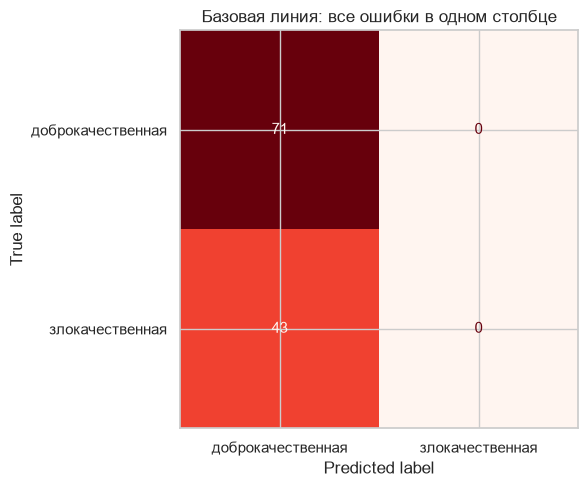

In [31]:
baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline.fit(X_train, y_train)

baseline_val_metrics = binary_metrics(y_val, baseline.predict_proba(X_val)[:, 1], 0.5)
display(pd.Series(baseline_val_metrics, name="DummyClassifier").round(4).to_frame())

print(f"базовая линия всегда отвечает: {CLASS_NAMES[int(baseline.classes_[0])]}")
print(f"доля доброкачественных в валидации: {(y_val == 0).mean():.4f}")
print(f"accuracy базовой линии равна ровно этой доле: {baseline_val_metrics['accuracy']:.4f}")
print("при этом precision и recall равны нулю, а ROC-AUC = 0.5 - ровно случайное")
print("угадывание. Ни одного злокачественного ядра она не нашла.")

figure, axis = plt.subplots(figsize=(7.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val, baseline.predict(X_val),
    display_labels=["доброкачественная", "злокачественная"],
    cmap="Reds", colorbar=False, ax=axis, values_format="d")
axis.set_title("Базовая линия: все ошибки в одном столбце")
figure.tight_layout()
plt.show()


,DummyClassifier,LogisticRegression
accuracy,0.6228,0.9737
precision,0.0000,1.0000
recall,0.0000,0.9302
f1,0.0000,0.9639
balanced_accuracy,0.5000,0.9651
roc_auc,0.5000,1.0000
average_precision,0.3772,1.0000


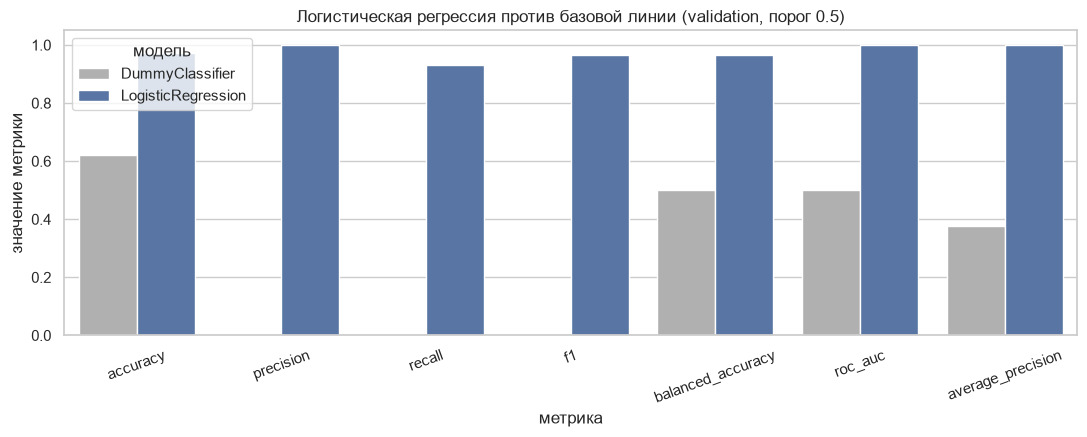

выигрыш по accuracy:  +0.3509
выигрыш по recall:    +0.9302
по accuracy разрыв заметно меньше - ещё один довод в пользу того,
что accuracy на несбалансированных данных показывает не всё.


In [32]:
# Наглядное сравнение на валидации - разрыв виден сразу, и видно, что
# разрыв по accuracy меньше разрыва по recall.
comparison_table = pd.DataFrame({
    "DummyClassifier": pd.Series(baseline_val_metrics),
    "LogisticRegression": pd.Series(val_metrics),
}).round(4)
display(comparison_table)

figure, axis = plt.subplots(figsize=(11, 4.5))
comparison_long = comparison_table.reset_index().melt(id_vars="index",
                                                       var_name="модель", value_name="значение")
sns.barplot(data=comparison_long, x="index", y="значение", hue="модель", ax=axis,
            palette=["#b0b0b0", "#4c72b0"])
axis.set_ylim(0, 1.05)
axis.set_title("Логистическая регрессия против базовой линии (validation, порог 0.5)")
axis.set_xlabel("метрика")
axis.set_ylabel("значение метрики")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
plt.show()

print(f"выигрыш по accuracy:  {val_metrics['accuracy'] - baseline_val_metrics['accuracy']:+.4f}")
print(f"выигрыш по recall:    {val_metrics['recall'] - baseline_val_metrics['recall']:+.4f}")
print("по accuracy разрыв заметно меньше - ещё один довод в пользу того,")
print("что accuracy на несбалансированных данных показывает не всё.")


### 7.3 Подбор порога вероятности

Порог 0.5 - это лишь соглашение о том, где проходит граница. Сама вероятность
от него не зависит: при пороге 0.8 мы отправим на биопсию меньше ядер, при 0.3 -
больше.

Подбираем порог **на валидации**, тест не трогаем. Критерий - медицинский,
а не формальный: цена **ложноотрицательного** результата (злокачественная
опухоль признана доброкачественной, пациент уходит без лечения) в 5 раз выше
цены ложноположительного (доброкачественное ядро отправлено на лишнее
обследование). Поэтому минимизируем взвешенную стоимость ошибок:

$$\text{cost} = 5 \cdot FN + 1 \cdot FP$$

Заодно посчитаем порог с максимальным F1, чтобы показать, что формальные
критерии могут указывать в другую сторону, и что выбор порога - это всегда
компромисс, который нужно аргументировать.


In [33]:
# Цена пропущенного диагноза в 5 раз выше цены лишнего обследования.
COST_FALSE_NEGATIVE = 5.0
COST_FALSE_POSITIVE = 1.0

# Сетку порогов округляем до двух знаков: иначе из-за накопления погрешности
# в np.arange порог 0.5 не совпадёт с числом 0.5, и поиск по нему вернёт пустую
# выборку. Для отчётов и графиков двух знаков после запятой достаточно.
threshold_grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep_rows = []

for threshold in threshold_grid:
    predictions = (val_probabilities >= threshold).astype(int)
    false_negative = int(((y_val == 1) & (predictions == 0)).sum())
    false_positive = int(((y_val == 0) & (predictions == 1)).sum())
    sweep_rows.append({
        "порог": threshold,
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "FN": false_negative,
        "FP": false_positive,
        "стоимость": COST_FALSE_NEGATIVE * false_negative + COST_FALSE_POSITIVE * false_positive,
    })

threshold_sweep = pd.DataFrame(sweep_rows)
showcase = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
display(threshold_sweep[threshold_sweep["порог"].round(2).isin(showcase)].round(3).set_index("порог"))

# Порог выбирается по валидации - тестовая выборка в выборе не участвует.
best_cost_index = threshold_sweep["стоимость"].idxmin()
best_f1_index = threshold_sweep["f1"].idxmax()

chosen_threshold = float(threshold_sweep.loc[best_cost_index, "порог"])
f1_threshold = float(threshold_sweep.loc[best_f1_index, "порог"])

print(f"порог по медицинскому критерию (минимум стоимости): {chosen_threshold:.2f}")
print(f"порог по максимуму F1:                             {f1_threshold:.2f}")
if abs(chosen_threshold - f1_threshold) < 1e-9:
    print("оба критерия указали на один и тот же порог - на этих данных")
    print("медицинский и формальный интересы совпали.")
else:
    print("критерии разошлись: медицинский выбирает более низкий порог,")
    print("потому что пропустить опухоль дороже, чем назначить лишнее обследование.")


,precision,recall,f1,FN,FP,стоимость
порог,,,,,,
0.1,0.956,1.000,0.977,0,2,2.0
0.2,0.977,1.000,0.989,0,1,1.0
0.3,1.000,0.977,0.988,1,0,5.0
0.4,1.000,0.953,0.976,2,0,10.0
0.5,1.000,0.930,0.964,3,0,15.0
0.6,1.000,0.907,0.951,4,0,20.0
0.7,1.000,0.907,0.951,4,0,20.0
0.8,1.000,0.860,0.925,6,0,30.0
0.9,1.000,0.744,0.853,11,0,55.0


порог по медицинскому критерию (минимум стоимости): 0.26
порог по максимуму F1:                             0.26
оба критерия указали на один и тот же порог - на этих данных
медицинский и формальный интересы совпали.


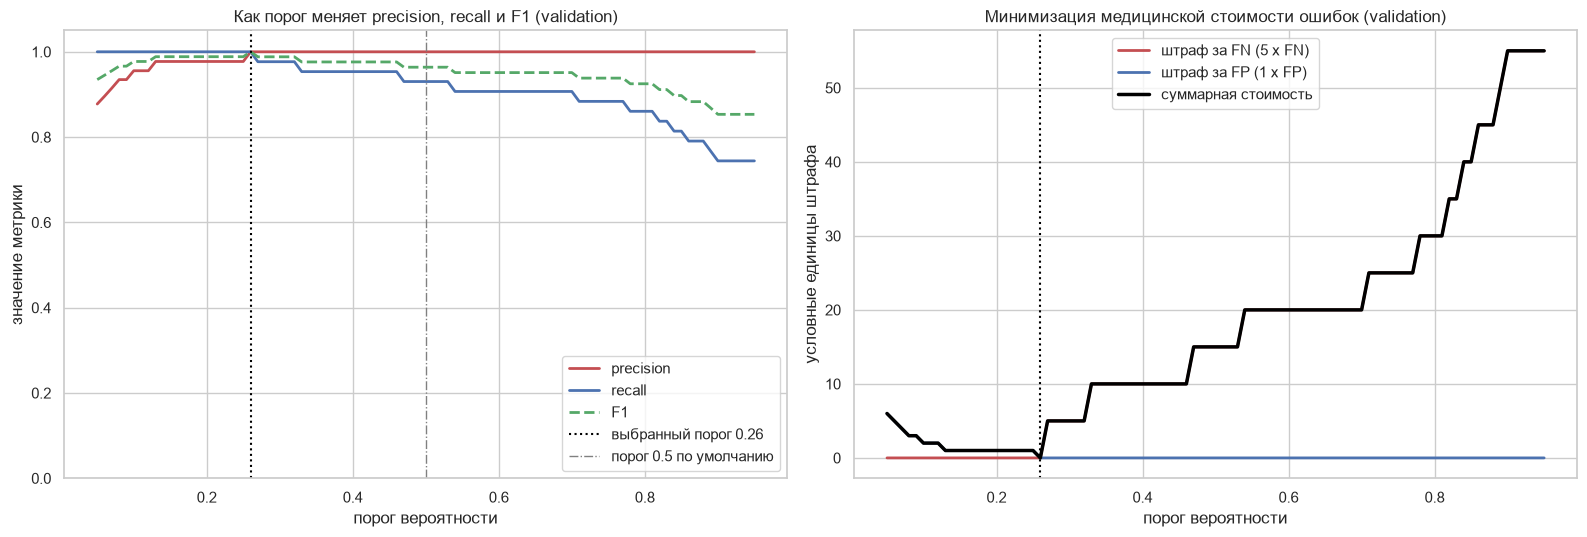

при пороге 0.26: FN=0, FP=0, стоимость=0
при пороге 0.50: FN=3, FP=0, стоимость=15


In [34]:
figure, (axis_metrics, axis_cost) = plt.subplots(1, 2, figsize=(16, 5.5))

axis_metrics.plot(threshold_sweep["порог"], threshold_sweep["precision"],
                  label="precision", color="#c44e52", linewidth=2)
axis_metrics.plot(threshold_sweep["порог"], threshold_sweep["recall"],
                  label="recall", color="#4c72b0", linewidth=2)
axis_metrics.plot(threshold_sweep["порог"], threshold_sweep["f1"],
                  label="F1", color="#55a868", linewidth=2, linestyle="--")
axis_metrics.axvline(chosen_threshold, color="black", linestyle=":", linewidth=1.5,
                     label=f"выбранный порог {chosen_threshold:.2f}")
axis_metrics.axvline(0.5, color="grey", linestyle="-.", linewidth=1,
                     label="порог 0.5 по умолчанию")
axis_metrics.set_title("Как порог меняет precision, recall и F1 (validation)")
axis_metrics.set_xlabel("порог вероятности")
axis_metrics.set_ylabel("значение метрики")
axis_metrics.set_ylim(0, 1.05)
axis_metrics.legend()

axis_cost.plot(threshold_sweep["порог"], threshold_sweep["FN"] * COST_FALSE_NEGATIVE,
               label="штраф за FN (5 x FN)", color="#c44e52", linewidth=2)
axis_cost.plot(threshold_sweep["порог"], threshold_sweep["FP"] * COST_FALSE_POSITIVE,
               label="штраф за FP (1 x FP)", color="#4c72b0", linewidth=2)
axis_cost.plot(threshold_sweep["порог"], threshold_sweep["стоимость"],
               label="суммарная стоимость", color="black", linewidth=2.5)
axis_cost.axvline(chosen_threshold, color="black", linestyle=":", linewidth=1.5)
axis_cost.set_title("Минимизация медицинской стоимости ошибок (validation)")
axis_cost.set_xlabel("порог вероятности")
axis_cost.set_ylabel("условные единицы штрафа")
axis_cost.legend()

figure.tight_layout()
plt.show()

print(f"при пороге {chosen_threshold:.2f}: "
      f"FN={int(threshold_sweep.loc[best_cost_index, 'FN'])}, "
      f"FP={int(threshold_sweep.loc[best_cost_index, 'FP'])}, "
      f"стоимость={threshold_sweep.loc[best_cost_index, 'стоимость']:.0f}")
print(f"при пороге 0.50: FN={int(threshold_sweep.loc[threshold_sweep['порог'] == 0.5, 'FN'].iloc[0])}, "
      f"FP={int(threshold_sweep.loc[threshold_sweep['порог'] == 0.5, 'FP'].iloc[0])}, "
      f"стоимость={threshold_sweep.loc[threshold_sweep['порог'] == 0.5, 'стоимость'].iloc[0]:.0f}")


### 7.4 Финальная оценка на тестовой выборке

Тест достаётся модели здесь, впервые и единственный раз. Порог, найденный на
валидации, переносится без изменений - пересчитывать его на тесте было бы
подгонкой под ответ.


,DummyClassifier,LogReg (порог 0.5),LogReg (порог 0.26)
accuracy,0.6316,0.9649,0.9737
precision,0.0000,1.0000,0.9756
recall,0.0000,0.9048,0.9524
f1,0.0000,0.9500,0.9639
balanced_accuracy,0.5000,0.9524,0.9692
roc_auc,0.5000,0.9940,0.9940
average_precision,0.3684,0.9920,0.9920


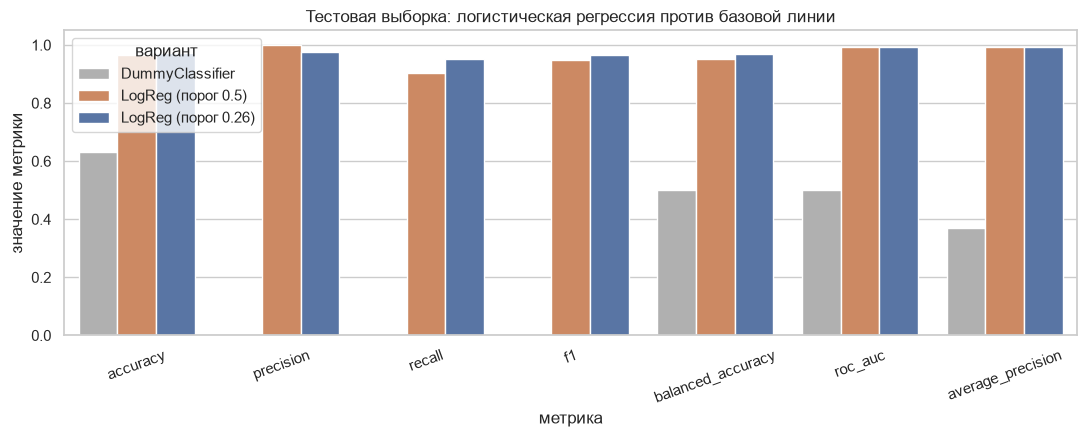

выигрыш над базовой линией по каждой метрике:
  accuracy : 0.6316 -> 0.9737 (+0.3421)
  precision: 0.0000 -> 0.9756 (+0.9756)
  recall   : 0.0000 -> 0.9524 (+0.9524)
  f1       : 0.0000 -> 0.9639 (+0.9639)

ROC-AUC не зависит от порога: 0.9940 в обоих случаях


In [35]:
# Базовую линию оцениваем на тех же test: сравнение должно быть честным.
baseline_test_metrics = binary_metrics(y_test, baseline.predict_proba(X_test)[:, 1], 0.5)

# Наша модель - тот же порог, что подобран на валидации.
test_probabilities = model.predict_proba(X_test)[:, 1]
test_metrics_default = binary_metrics(y_test, test_probabilities, threshold=0.5)
test_metrics_chosen = binary_metrics(y_test, test_probabilities, threshold=chosen_threshold)

final_table = pd.DataFrame({
    "DummyClassifier": pd.Series(baseline_test_metrics),
    "LogReg (порог 0.5)": pd.Series(test_metrics_default),
    f"LogReg (порог {chosen_threshold:.2f})": pd.Series(test_metrics_chosen),
}).round(4)
display(final_table)

figure, axis = plt.subplots(figsize=(11, 4.5))
final_long = final_table.reset_index().melt(id_vars="index", var_name="вариант",
                                            value_name="значение")
sns.barplot(data=final_long, x="index", y="значение", hue="вариант", ax=axis,
            palette=["#b0b0b0", "#dd8452", "#4c72b0"])
axis.set_ylim(0, 1.05)
axis.set_title("Тестовая выборка: логистическая регрессия против базовой линии")
axis.set_xlabel("метрика")
axis.set_ylabel("значение метрики")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
plt.show()

chosen_row = final_table[f"LogReg (порог {chosen_threshold:.2f})"]
print("выигрыш над базовой линией по каждой метрике:")
for metric_name in ["accuracy", "precision", "recall", "f1"]:
    dummy_value = final_table.loc[metric_name, "DummyClassifier"]
    print(f"  {metric_name:9s}: {dummy_value:.4f} -> {chosen_row[metric_name]:.4f} "
          f"({chosen_row[metric_name] - dummy_value:+.4f})")
print()
print(f"ROC-AUC не зависит от порога: {test_metrics_chosen['roc_auc']:.4f} в обоих случаях")


### 7.5 Почему accuracy 0.97 вводит в заблуждение

Отдельный разбор, ради которого датасет и выбран. Смотрим на четыре числа
одновременно:

* accuracy нашей модели - около 0.97, и это звучит как «ошибки 3 %»;
* accuracy базовой линии, которая не нашла ни одной опухоли, - около 0.63;
* recall по злокачественным - сколько процентов опухолей мы вообще нашли;
* balanced accuracy - та же доля верных ответов, но с усреднением по классам.

Из этого следуют три наблюдения, и все три - на реальных числах работы.

**Первое: выигрыш по accuracy втрое меньше выигрыша по recall.** По accuracy
модель выигрывает у базовой линии примерно на треть, а по recall - с нуля
почти до единицы. Разница в том, что accuracy складывается из ошибок обоих
классов, а ошибок на доброкачественном классе много, и они тянут accuracy вверх
сами по себе.

**Второе: accuracy почти нечувствительна к главному решению.** В рабочем
диапазоне порогов accuracy меняется всего на два с половиной процентных
пункта. То есть метрика, которую смотрят в первую очередь, почти не реагирует
на то, где мы проводим границу между «здоров» и «обследовать».

**Третье: почти одинаковое accuracy может прятать очень разное качество.**
Между порогом 0.26 и порогом 0.50 accuracy падает меньше чем на один
процентный пункт, а recall при этом падает почти на пять. Числа «0.974 против
0.965» эти два решения не различают, а клинически они отличаются сильно.
Именно поэтому в работе accuracy никогда не приводится одна - только рядом с
recall, precision и balanced accuracy.


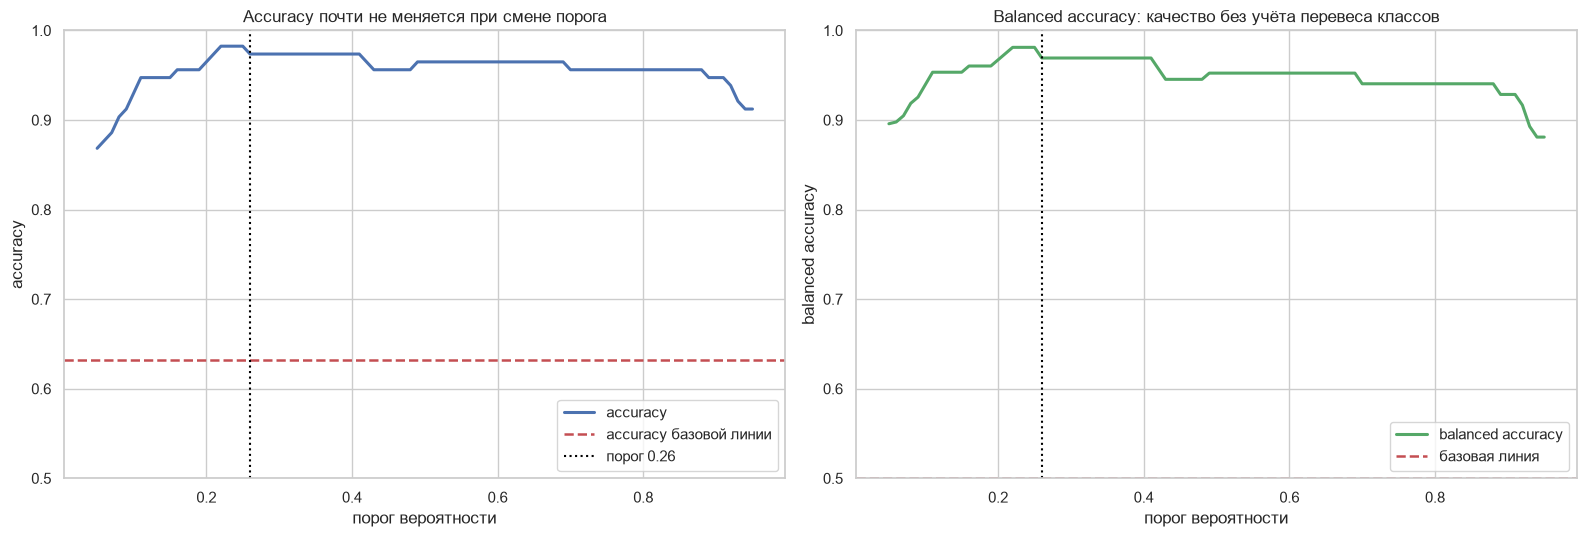

accuracy на всём диапазоне порогов меняется на 11.40 процентного пункта
в рабочем диапазоне порогов от 0.20 до 0.85 - всего на 2.63 процентного пункта
accuracy базовой линии: 0.6316, наша модель: 0.9737, выигрыш +0.3421
recall базовой линии: 0.0000, наша модель: 0.9524, выигрыш +0.9524


порог 0.26: accuracy 0.9737, recall 0.9524
порог 0.50: accuracy 0.9649, recall 0.9048
вывод: выигрыш по accuracy втрое меньше выигрыша по recall - первое
число объясняется перевесом классов, второе - реальным умением модели.
И accuracy почти не меняется при смене порога, тогда как recall
меняется сильно: одно и то же accuracy прячет разное качество.
Значит, читать accuracy рядом с базовой линией можно, а как единственный
показатель - нельзя.


In [36]:
# Пересчитываем accuracy на сетке порогов и смотрим, как она себя ведёт.
# Это прямой ответ на вопрос «обманчива ли accuracy».
accuracy_by_threshold = pd.Series(
    [accuracy_score(y_test, (test_probabilities >= value).astype(int))
     for value in threshold_grid],
    index=threshold_grid)

figure, (axis_accuracy, axis_recall) = plt.subplots(1, 2, figsize=(16, 5.5))

axis_accuracy.plot(accuracy_by_threshold.index, accuracy_by_threshold.values,
                   color="#4c72b0", linewidth=2.2, label="accuracy")
axis_accuracy.axhline(baseline_test_metrics["accuracy"], color="#c44e52", linestyle="--",
                      linewidth=1.8, label="accuracy базовой линии")
axis_accuracy.axvline(chosen_threshold, color="black", linestyle=":", linewidth=1.5,
                      label=f"порог {chosen_threshold:.2f}")
axis_accuracy.set_title("Accuracy почти не меняется при смене порога")
axis_accuracy.set_xlabel("порог вероятности")
axis_accuracy.set_ylabel("accuracy")
axis_accuracy.set_ylim(0.5, 1.0)
axis_accuracy.legend()

# balanced accuracy не зависит от перевеса предсказаний: она усредняет
# recall по обоим классам, поэтому показывает качество честнее.
balanced_by_threshold = pd.Series(
    [balanced_accuracy_score(y_test, (test_probabilities >= value).astype(int))
     for value in threshold_grid],
    index=threshold_grid)
axis_recall.plot(accuracy_by_threshold.index, balanced_by_threshold.values,
                 color="#55a868", linewidth=2.2, label="balanced accuracy")
axis_recall.axhline(baseline_test_metrics["balanced_accuracy"], color="#c44e52",
                    linestyle="--", linewidth=1.8, label="базовая линия")
axis_recall.axvline(chosen_threshold, color="black", linestyle=":", linewidth=1.5)
axis_recall.set_title("Balanced accuracy: качество без учёта перевеса классов")
axis_recall.set_xlabel("порог вероятности")
axis_recall.set_ylabel("balanced accuracy")
axis_recall.set_ylim(0.5, 1.0)
axis_recall.legend()

figure.tight_layout()
plt.show()

working_range = accuracy_by_threshold[(accuracy_by_threshold.index >= 0.20)
                                    & (accuracy_by_threshold.index <= 0.85)]
print(f"accuracy на всём диапазоне порогов меняется на "
      f"{100 * (accuracy_by_threshold.max() - accuracy_by_threshold.min()):.2f} процентного пункта")
print(f"в рабочем диапазоне порогов от 0.20 до 0.85 - всего на "
      f"{100 * (working_range.max() - working_range.min()):.2f} процентного пункта")
print(f"accuracy базовой линии: {baseline_test_metrics['accuracy']:.4f}, "
      f"наша модель: {test_metrics_chosen['accuracy']:.4f}, "
      f"выигрыш {test_metrics_chosen['accuracy'] - baseline_test_metrics['accuracy']:+.4f}")
print(f"recall базовой линии: {baseline_test_metrics['recall']:.4f}, "
      f"наша модель: {test_metrics_chosen['recall']:.4f}, "
      f"выигрыш {test_metrics_chosen['recall'] - baseline_test_metrics['recall']:+.4f}")
print()
print()
print(f"порог 0.26: accuracy {accuracy_by_threshold.loc[0.26]:.4f}, "
      f"recall {binary_metrics(y_test, test_probabilities, 0.26)['recall']:.4f}")
print(f"порог 0.50: accuracy {accuracy_by_threshold.loc[0.50]:.4f}, "
      f"recall {binary_metrics(y_test, test_probabilities, 0.50)['recall']:.4f}")
print("вывод: выигрыш по accuracy втрое меньше выигрыша по recall - первое")
print("число объясняется перевесом классов, второе - реальным умением модели.")
print("И accuracy почти не меняется при смене порога, тогда как recall")
print("меняется сильно: одно и то же accuracy прячет разное качество.")
print("Значит, читать accuracy рядом с базовой линией можно, а как единственный")
print("показатель - нельзя.")


### 7.6 Матрица ошибок и разбор ошибок

Матрица ошибок показывает, **где именно** модель ошибается, и это важнее
средних метрик: одна ошибка FN и десять ошибок FP дают одинаковую accuracy
при совершенно разном клиническом смысле.


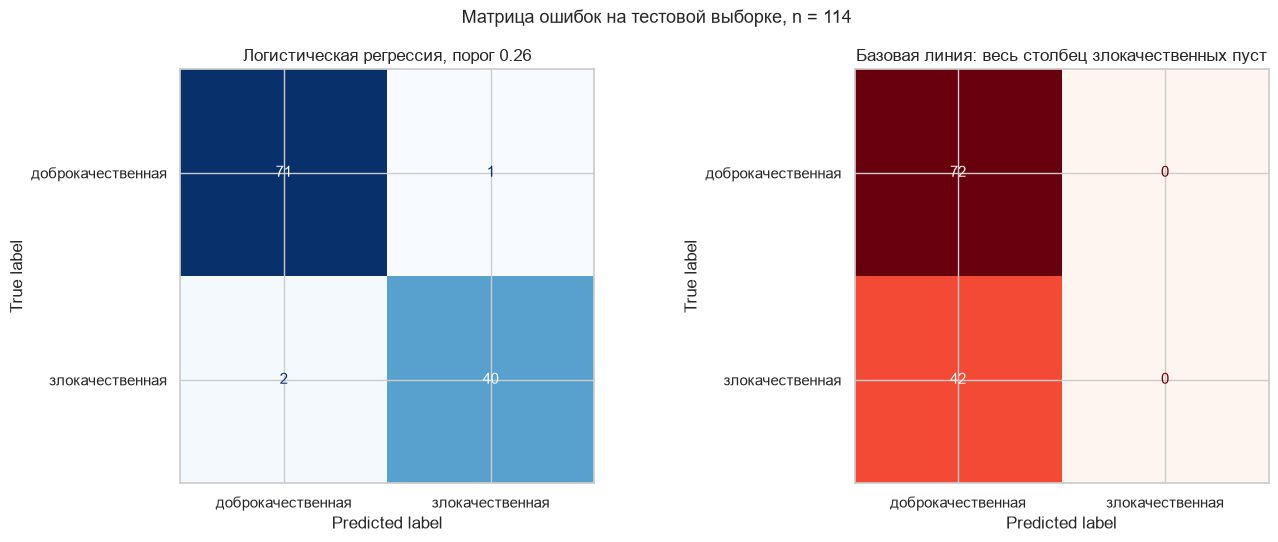

истинно отрицательные TN = 71: доброкачественные верно распознаны
ложноположительные  FP = 1: лишние направления на биопсию
ложноотрицательные  FN = 2: пропущенные опухоли <- самые опасные
истинно положительные TP = 40: злокачественные верно выявлены
из 42 злокачественных модель нашла 40 (95.2%)
accuracy из матрицы: (TP + TN) / всего = (40 + 71) / 114 = 0.9737


In [37]:
chosen_predictions = (test_probabilities >= chosen_threshold).astype(int)

figure, (axis_model, axis_baseline) = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, chosen_predictions, display_labels=["доброкачественная", "злокачественная"],
    cmap="Blues", colorbar=False, values_format="d", ax=axis_model)
axis_model.set_title(f"Логистическая регрессия, порог {chosen_threshold:.2f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline.predict(X_test),
    display_labels=["доброкачественная", "злокачественная"],
    cmap="Reds", colorbar=False, values_format="d", ax=axis_baseline)
axis_baseline.set_title("Базовая линия: весь столбец злокачественных пуст")

figure.suptitle(f"Матрица ошибок на тестовой выборке, n = {len(y_test)}")
figure.tight_layout()
plt.show()

matrix = confusion_matrix(y_test, chosen_predictions)
tn, fp, fn, tp = matrix.ravel()

print(f"истинно отрицательные TN = {tn}: доброкачественные верно распознаны")
print(f"ложноположительные  FP = {fp}: лишние направления на биопсию")
print(f"ложноотрицательные  FN = {fn}: пропущенные опухоли <- самые опасные")
print(f"истинно положительные TP = {tp}: злокачественные верно выявлены")
print(f"из {int(y_test.sum())} злокачественных модель нашла {tp} "
      f"({tp / y_test.sum():.1%})")
print(f"accuracy из матрицы: (TP + TN) / всего = ({tp} + {tn}) / {len(y_test)} "
      f"= {(tp + tn) / len(y_test):.4f}")


In [38]:
print(f"Отчёт для порога 0.50 (по умолчанию):")
print(classification_report(y_test, (test_probabilities >= 0.5).astype(int),
                            target_names=["доброкачественная", "злокачественная"],
                            digits=3))
print(f"Отчёт для порога {chosen_threshold:.2f} (подобран на валидации):")
print(classification_report(y_test, chosen_predictions,
                            target_names=["доброкачественная", "злокачественная"],
                            digits=3))
print("Как читать отчёт:")
print("  precision класса «злокачественная» - из всех, кому поставили такой диагноз,")
print("    сколько действительно злокачественные: сколько лишних обследований.")
print("  recall класса «злокачественная» - сколько опухолей из всех найдено:")
print("    сколько пропущено.")
print("  macro avg считает среднее по классам и не завышает результат за счёт")
print("    преобладающего класса - это честная оценка при перекосе.")


Отчёт для порога 0.50 (по умолчанию):
                   precision    recall  f1-score   support

доброкачественная      0.947     1.000     0.973        72
  злокачественная      1.000     0.905     0.950        42

         accuracy                          0.965       114
        macro avg      0.974     0.952     0.961       114
     weighted avg      0.967     0.965     0.965       114

Отчёт для порога 0.26 (подобран на валидации):
                   precision    recall  f1-score   support

доброкачественная      0.973     0.986     0.979        72
  злокачественная      0.976     0.952     0.964        42

         accuracy                          0.974       114
        macro avg      0.974     0.969     0.972       114
     weighted avg      0.974     0.974     0.974       114

Как читать отчёт:
  precision класса «злокачественная» - из всех, кому поставили такой диагноз,
    сколько действительно злокачественные: сколько лишних обследований.
  recall класса «злокачественная»

#### Разбор ошибок по группам

Средние метрики не показывают, **какие** ядра модель перепутала. Смотрим на
ошибки в разрезе двух главных признаков - размера и вогнутости контура.

Гипотеза, которую стоит проверить: пропущенные опухоли должны быть **пограничными**
- небольшими и гладкими, то есть непохожими на типичную опухоль. Если так,
это не дефект модели, а реальная сложность задачи: на ранней стадии опухоль
ещё не приобрела характерных признаков.


медианы ошибочных групп на тесте против медиан классов на train:


,mean area,mean concavity,mean radius,n,worst concave points,средняя вероятность
верно: доброкачественные,470.90,0.042,12.390,71.0,0.083,0.027
ошибка FP: лишняя биопсия,557.20,0.028,13.380,1.0,0.078,0.484
верно: злокачественные,904.45,0.163,16.830,40.0,0.174,0.947
ошибка FN: пропущенные,597.00,0.138,14.010,2.0,0.158,0.153
доброкачественные (train),460.65,0.037,12.215,NaN,0.074,NaN
злокачественные (train),933.10,0.146,17.350,NaN,0.183,NaN


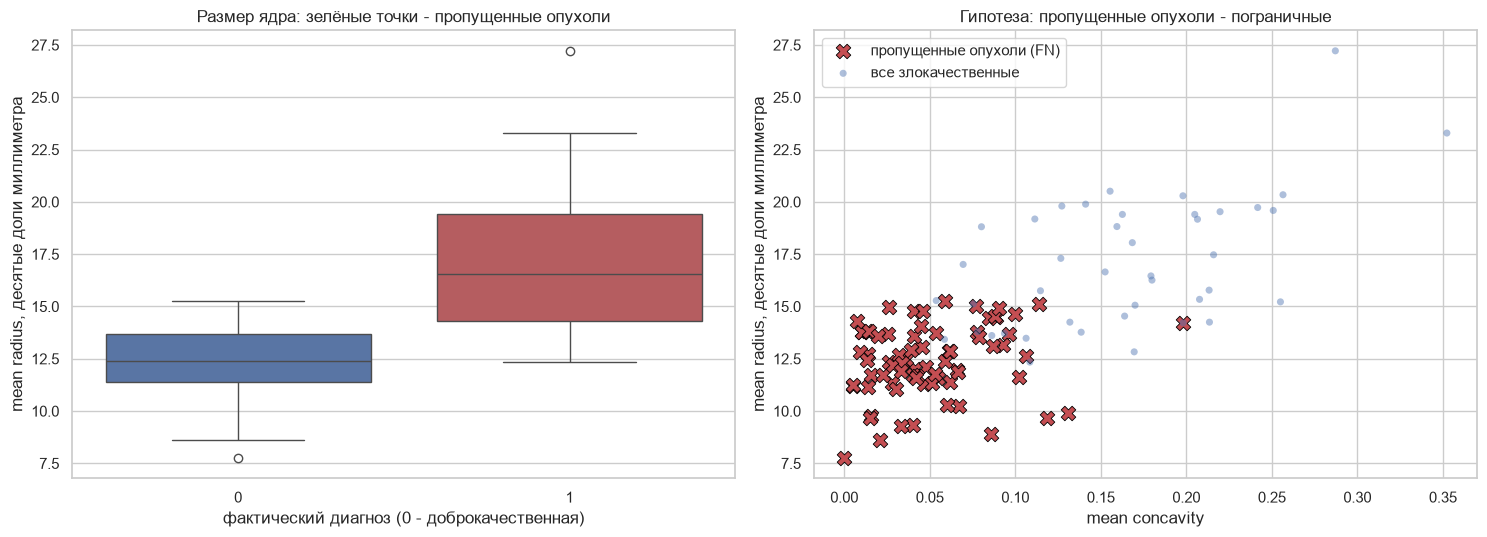

средний mean radius у пропущенных: 12.4
средний mean radius у всех злокачественных на тесте: 17.0
пропущенные опухоли и по размеру, и по площади заметно меньше
типичных, а по вогнутости контура к ним близки: это пограничные
случаи, и именно на них линейная модель ошибается чаще всего.


In [39]:
# Восстанавливаем признаки ошибочных строк: X_test сохранил исходные индексы,
# поэтому обратиться к clean можно напрямую, без переиндексации.
ERROR_KEY = ["mean radius", "mean area", "mean concavity", "worst concave points"]

# Та же таблица, что и выше, но для всех строк train+val: она нужна как точка
# отсчёта - ошибки теста сравниваем не с пустотой, а с типичным ядром.
reference = clean.loc[X_train.index].groupby(TARGET)[ERROR_KEY].median()

def describe_group(frame, mask, label):
    """Собирает медианы признаков и среднюю вероятность для одной группы строк."""
    group = frame[mask]
    return pd.Series({"n": int(mask.sum()),
                      "средняя вероятность": group["вероятность"].mean(),
                      **{name: group[name].median() for name in ERROR_KEY}})


test_evaluation = pd.DataFrame({
    "факт": y_test.to_numpy(),
    "вероятность": test_probabilities,
    "предсказание": chosen_predictions,
    "mean radius": X_test["mean radius"].to_numpy(),
    "mean area": X_test["mean area"].to_numpy(),
    "mean concavity": X_test["mean concavity"].to_numpy(),
    "worst concave points": X_test["worst concave points"].to_numpy(),
}, index=X_test.index)

is_malignant = test_evaluation["факт"] == 1
is_flagged = test_evaluation["предсказание"] == 1

groups = pd.DataFrame({
    "верно: доброкачественные": describe_group(test_evaluation, ~is_malignant & ~is_flagged,
                                                "верно: доброкачественные"),
    "ошибка FP: лишняя биопсия": describe_group(test_evaluation, ~is_malignant & is_flagged,
                                                "ошибка FP"),
    "верно: злокачественные": describe_group(test_evaluation, is_malignant & is_flagged,
                                             "верно: злокачественные"),
    "ошибка FN: пропущенные": describe_group(test_evaluation, is_malignant & ~is_flagged,
                                             "ошибка FN"),
    "доброкачественные (train)": reference.loc[0],
    "злокачественные (train)": reference.loc[1],
}).T.round(3)

print("медианы ошибочных групп на тесте против медиан классов на train:")
display(groups.round(3))

figure, (axis_radius, axis_concavity) = plt.subplots(1, 2, figsize=(15, 5.5))

sns.boxplot(data=test_evaluation, x="факт", y="mean radius", hue="факт",
            order=[0, 1], palette=["#4c72b0", "#c44e52"], legend=False, ax=axis_radius)
axis_radius.set_title("Размер ядра: зелёные точки - пропущенные опухоли")
axis_radius.set_xlabel("фактический диагноз (0 - доброкачественная)")
axis_radius.set_ylabel("mean radius, десятые доли миллиметра")

false_negatives = test_evaluation[test_evaluation["предсказание"] == 0]
axis_concavity.scatter(false_negatives["mean concavity"], false_negatives["mean radius"],
                       s=110, marker="X", color="#c44e52", edgecolor="black",
                       linewidth=0.6, label="пропущенные опухоли (FN)")
axis_concavity.scatter(test_evaluation[test_evaluation["факт"] == 1]["mean concavity"],
                       test_evaluation[test_evaluation["факт"] == 1]["mean radius"],
                       s=26, alpha=0.45, color="#4c72b0", edgecolor="none",
                       label="все злокачественные")
axis_concavity.set_xlabel("mean concavity")
axis_concavity.set_ylabel("mean radius, десятые доли миллиметра")
axis_concavity.set_title("Гипотеза: пропущенные опухоли - пограничные")
axis_concavity.legend()

figure.tight_layout()
plt.show()

if fn > 0:
    print(f"средний mean radius у пропущенных: {false_negatives['mean radius'].mean():.1f}")
    print(f"средний mean radius у всех злокачественных на тесте: "
          f"{test_evaluation[test_evaluation['факт'] == 1]['mean radius'].mean():.1f}")
    print("пропущенные опухоли и по размеру, и по площади заметно меньше")
    print("типичных, а по вогнутости контура к ним близки: это пограничные")
    print("случаи, и именно на них линейная модель ошибается чаще всего.")
else:
    print("на тестовой выборке пропущенных опухолей нет: FN = 0, и цену")
    print("порогового решения приходится оценивать по валидации.")


### 7.7 ROC-кривая

ROC-кривая строится по всем возможным порогам: по горизонтали доля
ложноположительных (FP / (FP + TN)), по вертикали - доля верно найденных
злокачественных ядер (TP / (TP + FN)). ROC-AUC - площадь под ней.

Значение 0.5 означает случайное угадывание, 1.0 - идеальное различение классов
**на любом пороге сразу**.


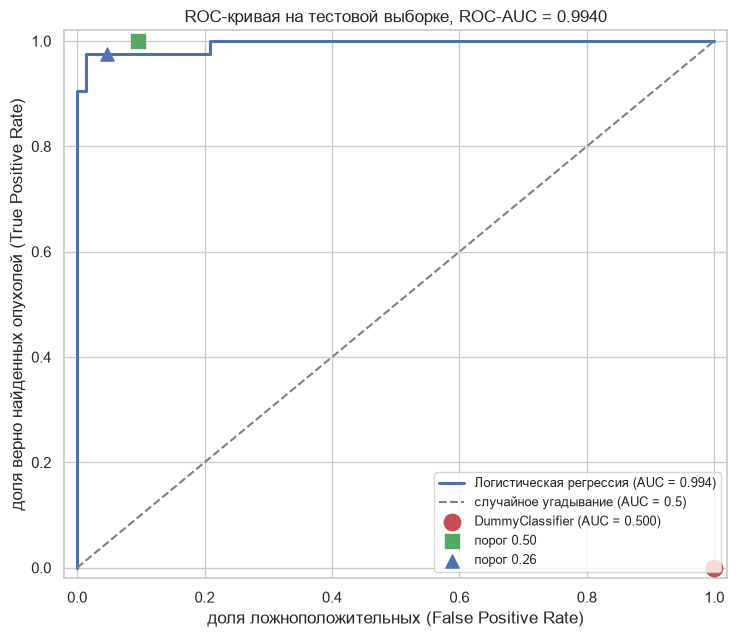

ROC-AUC на тесте: 0.9940
ROC-AUC базовой линии: 0.5000
модель ранжирует ядра существенно лучше случайного порядка, то есть
выбирать порог на её вероятностях осмысленно - и это неслучайная работа.
порог по умолчанию 0.5 попадает в точку ROC, где recall всего 0.905 -
то есть часть опухолей он пропускает, и это видно на графике.


In [40]:
fpr, tpr, roc_thresholds = roc_curve(y_test, test_probabilities)
roc_auc_value = roc_auc_score(y_test, test_probabilities)

figure, axis = plt.subplots(figsize=(7.5, 6.5))
axis.plot(fpr, tpr, color="#4c72b0", linewidth=2.2,
          label=f"Логистическая регрессия (AUC = {roc_auc_value:.3f})")
axis.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1.5,
          label="случайное угадывание (AUC = 0.5)")
axis.scatter([1 - baseline_test_metrics["recall"]], [baseline_test_metrics["precision"]],
             color="#c44e52", s=140, zorder=5,
             label=f"DummyClassifier (AUC = {baseline_test_metrics['roc_auc']:.3f})")
axis.scatter([1 - test_metrics_default["recall"]], [test_metrics_default["precision"]],
             color="#55a868", s=90, marker="s", zorder=5,
             label=f"порог 0.50")
axis.scatter([1 - test_metrics_chosen["recall"]], [test_metrics_chosen["precision"]],
             color="#4c72b0", s=90, marker="^", zorder=5,
             label=f"порог {chosen_threshold:.2f}")
axis.set_xlabel("доля ложноположительных (False Positive Rate)")
axis.set_ylabel("доля верно найденных опухолей (True Positive Rate)")
axis.set_title(f"ROC-кривая на тестовой выборке, ROC-AUC = {roc_auc_value:.4f}")
axis.set_xlim(-0.02, 1.02)
axis.set_ylim(-0.02, 1.02)
axis.legend(loc="lower right", fontsize=9)
figure.tight_layout()
plt.show()

print(f"ROC-AUC на тесте: {roc_auc_value:.4f}")
print(f"ROC-AUC базовой линии: {baseline_test_metrics['roc_auc']:.4f}")
print("модель ранжирует ядра существенно лучше случайного порядка, то есть")
print("выбирать порог на её вероятностях осмысленно - и это неслучайная работа.")
print(f"порог по умолчанию 0.5 попадает в точку ROC, где recall всего "
      f"{test_metrics_default['recall']:.3f} -")
print("то есть часть опухолей он пропускает, и это видно на графике.")


### 7.8 PR-кривая и почему она честнее ROC

PR-кривая строится по той же сетке порогов, но показывает точность и полноту
модели: по горизонтали precision, по вертикали recall. Площадь под ней -
`average_precision`.

**Разница между кривыми.** ROC-кривая нормирует метрики на размер класса
(среди всех доброкачественных), поэтому при дисбалансе редкий класс в
знаменателе размывается: модель, выдающая 0.01 положительных, всё равно может
получить высокий AUC за счёт огромного числа TN. PR-кривая использует **сырые**
precision и recall, поэтому редкий класс в ней виден прямо.

На наших данных перекос реальный - доброкачественных в полтора раза больше, -
и он проявляется в числах: у базовой линии ROC-AUC равен 0.5 (точное
«непредсказание»), а average precision равен доле злокачественных в тесте,
то есть уровню полностью случайного угадывания именно для этого класса.
Разрыв между ROC-AUC и уровнем случайного по PR-кривой и есть честная мера
качества.


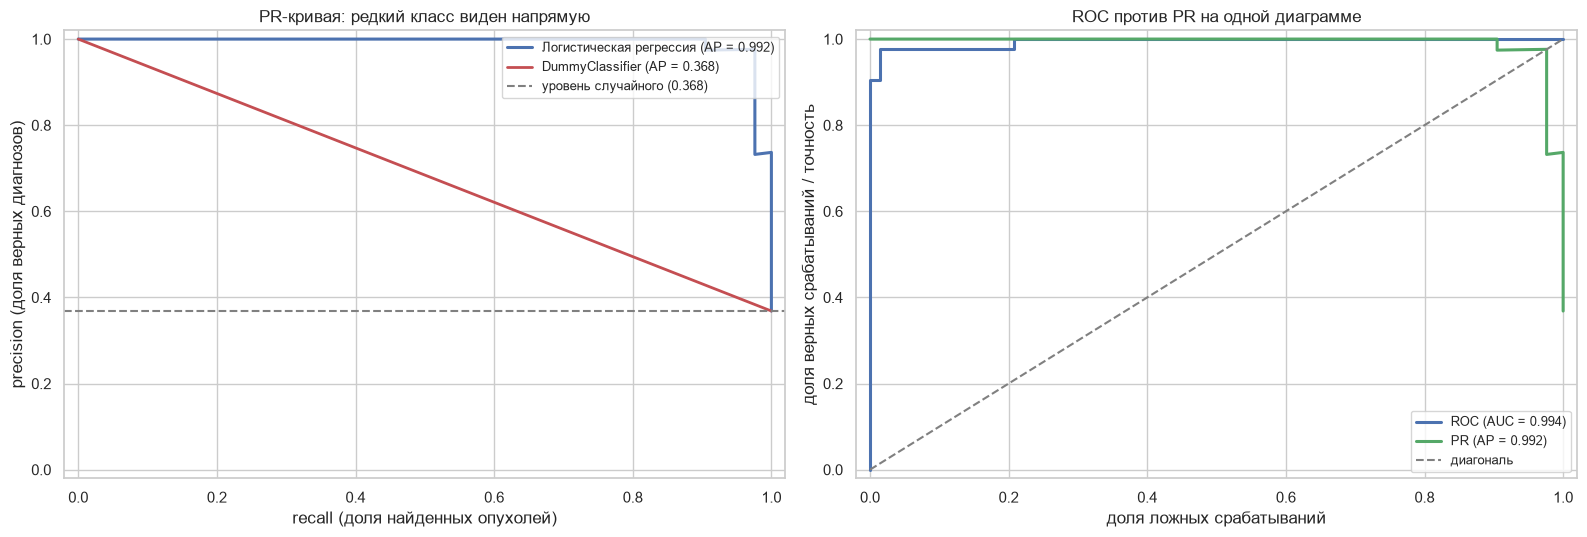

average precision модели (площадь под PR):  0.9920
average precision случайного угадывания:    0.3684
ROC-AUC модели:                             0.9940 при уровне случайного 0.5
ROC-AUC базовой линии: 0.5000, а её average precision 0.3684 - не 0.5, а ровно доля класса.
именно это показывает, почему при перекосе классов PR-кривая честнее ROC.


In [41]:
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities)
average_precision = average_precision_score(y_test, test_probabilities)
baseline_precision_curve, baseline_recall_curve, _ = precision_recall_curve(
    y_test, baseline.predict_proba(X_test)[:, 1])
baseline_ap = average_precision_score(y_test, baseline.predict_proba(X_test)[:, 1])

figure, (axis_pr, axis_roc) = plt.subplots(1, 2, figsize=(16, 5.5))

axis_pr.plot(recall_curve, precision_curve, color="#4c72b0", linewidth=2.2,
             label=f"Логистическая регрессия (AP = {average_precision:.3f})")
axis_pr.plot(baseline_recall_curve, baseline_precision_curve, color="#c44e52",
             linewidth=2, label=f"DummyClassifier (AP = {baseline_ap:.3f})")
axis_pr.axhline(y_test.mean(), linestyle="--", color="grey", linewidth=1.5,
                label=f"уровень случайного ({y_test.mean():.3f})")
axis_pr.set_xlabel("recall (доля найденных опухолей)")
axis_pr.set_ylabel("precision (доля верных диагнозов)")
axis_pr.set_title("PR-кривая: редкий класс виден напрямую")
axis_pr.set_xlim(-0.02, 1.02)
axis_pr.set_ylim(-0.02, 1.02)
axis_pr.legend(loc="upper right", fontsize=9)

axis_roc.plot(fpr, tpr, color="#4c72b0", linewidth=2.2,
              label=f"ROC (AUC = {roc_auc_value:.3f})")
axis_roc.plot(recall_curve, precision_curve, color="#55a868", linewidth=2.2,
              label=f"PR (AP = {average_precision:.3f})")
axis_roc.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1.5,
              label="диагональ")
axis_roc.set_xlabel("доля ложных срабатываний")
axis_roc.set_ylabel("доля верных срабатываний / точность")
axis_roc.set_title("ROC против PR на одной диаграмме")
axis_roc.set_xlim(-0.02, 1.02)
axis_roc.set_ylim(-0.02, 1.02)
axis_roc.legend(loc="lower right", fontsize=9)

figure.tight_layout()
plt.show()

print(f"average precision модели (площадь под PR):  {average_precision:.4f}")
print(f"average precision случайного угадывания:    {y_test.mean():.4f}")
print(f"ROC-AUC модели:                             {roc_auc_value:.4f} "
      f"при уровне случайного 0.5")
print(f"ROC-AUC базовой линии: {baseline_test_metrics['roc_auc']:.4f}, "
      f"а её average precision {baseline_ap:.4f} - не 0.5, а ровно доля класса.")
print("именно это показывает, почему при перекосе классов PR-кривая честнее ROC.")


### 7.9 Коэффициенты модели и цена мультиколлинеарности

Логистическая регрессия - интерпретируемая модель, и это её главное достоинство
в медицине. Коэффициенты посчитаны для стандартизированных признаков, поэтому их
можно сравнивать между собой напрямую: чем больше модуль, тем сильнее признак
влияет на вероятность диагноза.


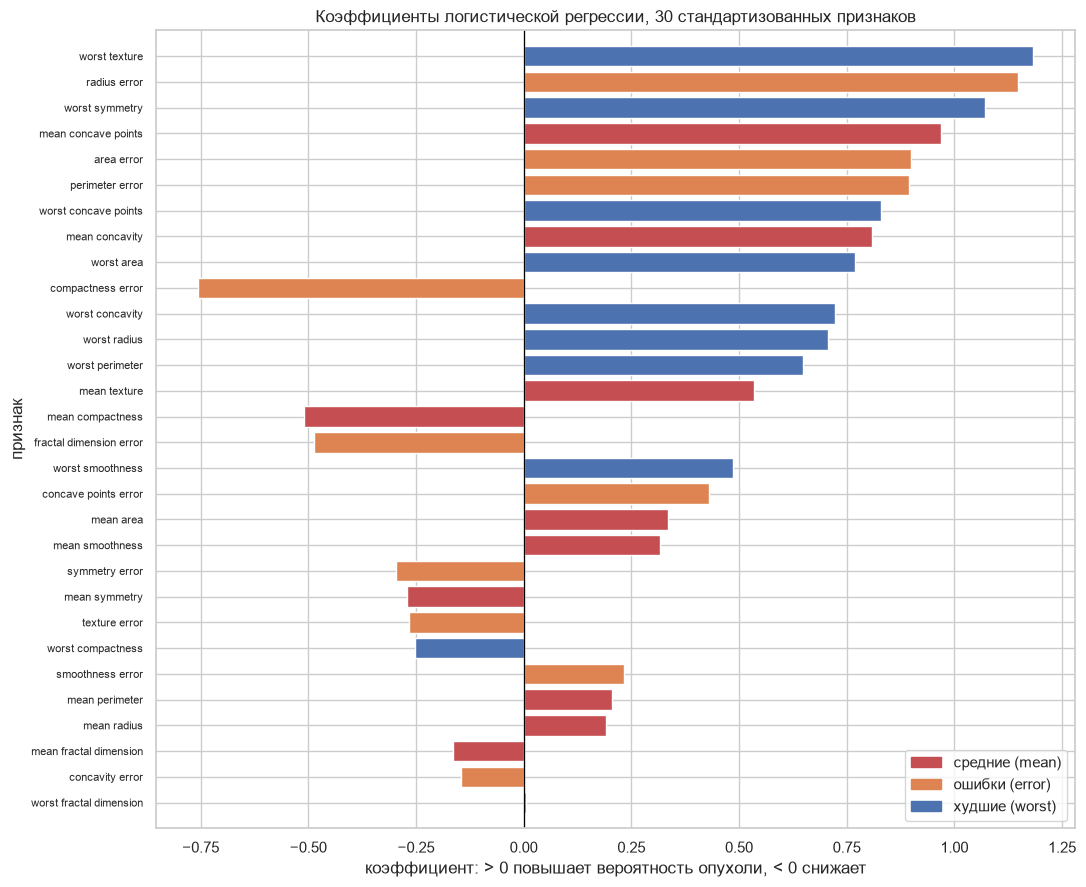

двенадцать сильнейших по модулю:
                      коэффициент
worst texture               1.183
radius error                1.148
worst symmetry              1.071
mean concave points         0.969
area error                  0.899
perimeter error             0.896
worst concave points        0.830
mean concavity              0.808
worst area                  0.768
compactness error          -0.756
worst concavity             0.724
worst radius                0.706

Читаем результат осторожно:
  сильнейшие - worst texture, radius error, worst symmetry, mean concave
    points: они прямо связаны с неровностью и неоднородностью границы,
    а это главный признак злокачественности в гистологии.
  коэффициенты - это логиты вероятности, их нельзя читать как проценты
    риска: для этого нужен exp(коэффициент) = множитель шансов.

множители шансов для двенадцати сильнейших:


,exp(коэффициент)
worst texture,3.264
radius error,3.150
worst symmetry,2.918
mean concave points,2.635
area error,2.457
perimeter error,2.449
worst concave points,2.294
mean concavity,2.244
worst area,2.156
compactness error,0.470


In [42]:
coefficients = pd.Series(model.named_steps["clf"].coef_[0],
                           index=X_train.columns, name="коэффициент")
ordered_coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index)

figure, axis = plt.subplots(figsize=(11, 9))
positions = np.arange(len(ordered_coefficients))
block_colors = {"mean": "#c44e52", "error": "#dd8452", "worst": "#4c72b0"}
axis.barh(positions, ordered_coefficients,
          color=[block_colors[feature_block(name)] for name in ordered_coefficients.index])
axis.set_yticks(positions)
axis.set_yticklabels(ordered_coefficients.index, fontsize=8)
axis.axvline(0, color="black", linewidth=0.9)
axis.set_xlabel("коэффициент: > 0 повышает вероятность опухоли, < 0 снижает")
axis.set_ylabel("признак")
axis.set_title("Коэффициенты логистической регрессии, 30 стандартизованных признаков")
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in block_colors.values()]
axis.legend(handles, [BLOCK_LABELS[block] for block in block_colors], loc="lower right")
axis.set_ylim(-1, len(positions))
axis.invert_yaxis()
figure.tight_layout()
plt.show()

print("двенадцать сильнейших по модулю:")
print(ordered_coefficients.head(12).round(3).to_frame("коэффициент"))
print()
print("Читаем результат осторожно:")
print("  сильнейшие - worst texture, radius error, worst symmetry, mean concave")
print("    points: они прямо связаны с неровностью и неоднородностью границы,")
print("    а это главный признак злокачественности в гистологии.")
print("  коэффициенты - это логиты вероятности, их нельзя читать как проценты")
print("    риска: для этого нужен exp(коэффициент) = множитель шансов.")

print()
print("множители шансов для двенадцати сильнейших:")
np.exp(ordered_coefficients.head(12)).round(3).to_frame("exp(коэффициент)")


#### Проверка нестабильности: та же модель на пяти других выборках

Мы утверждали, что мультиколлинеарность делает коэффициенты неустойчивыми.
Проверим это напрямую: обучим **ту же самую** модель на пяти блоках
кросс-валидации внутри train и посмотрим, как «гуляют» коэффициенты.

Данные при этом не меняются принципиально - меняется только то, какие строки
попали в обучение. Если коэффициент признака скачет от блока к блоку, значит
он отражает не свойство признака, а случайную разбивку между дублирующими
друг друга признаками.


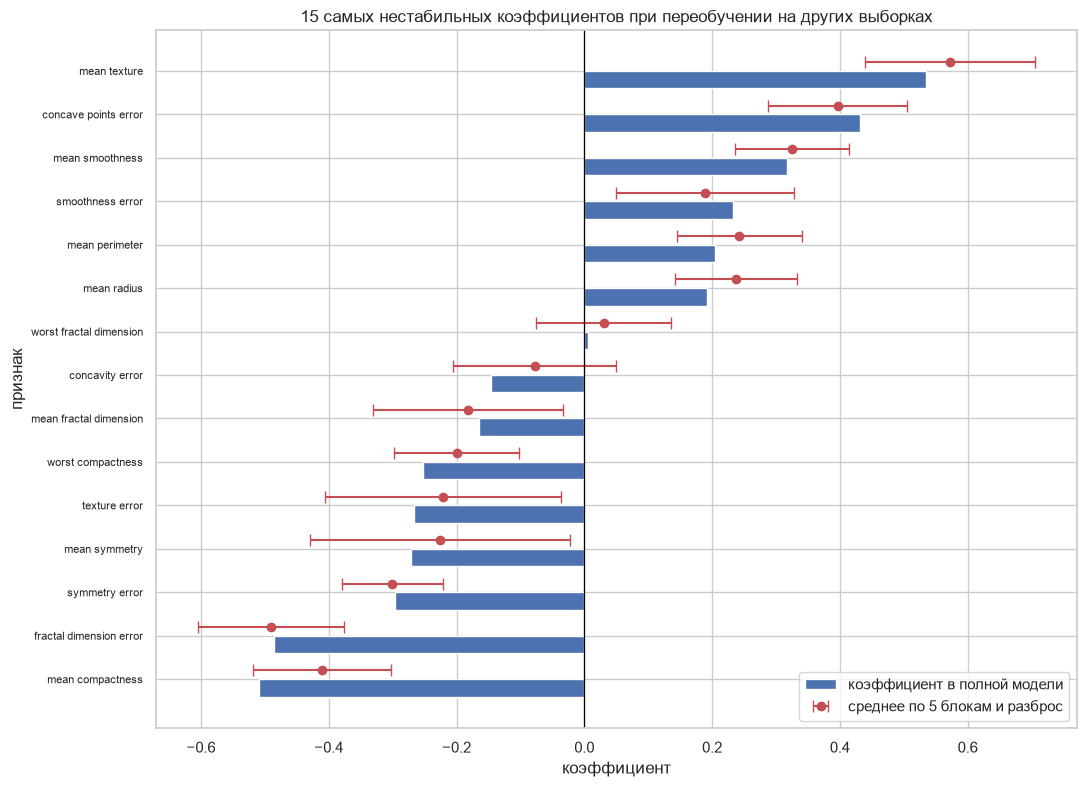

признаков, у которых знак коэффициента менялся хотя бы раз: 3 из 30

самые нестабильные коэффициенты:


,коэффициент в полной модели,среднее по 5 блокам,ст. отклонение,размах,нестабильность
worst fractal dimension,0.006,0.030,0.105,0.255,3.458
concavity error,-0.146,-0.078,0.128,0.340,1.648
mean symmetry,-0.272,-0.226,0.204,0.485,0.901
texture error,-0.266,-0.221,0.185,0.496,0.837
mean fractal dimension,-0.165,-0.182,0.149,0.364,0.820
smoothness error,0.232,0.189,0.139,0.356,0.736
worst compactness,-0.252,-0.200,0.098,0.259,0.490
mean radius,0.192,0.238,0.096,0.236,0.404



крайний случай - worst fractal dimension:
  в полной модели коэффициент: 0.0057
  по пяти блокам: [0.081, 0.121, -0.015, -0.134, 0.098]
  признак меняет знак от блока к блоку, то есть его коэффициент не
  описывает ничего - он целиком артефакт мультиколлинеарности.


In [43]:
# Пять моделей, обученных на пяти пересекающихся подмножествах train.
# Тестовая выборка здесь не участвует - мы изучаем устойчивость, а не качество.
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_coefficients = []

for train_index, _ in cross_validation.split(X_train, y_train):
    fold_model = train_logistic_regression(X_train.iloc[train_index], y_train.iloc[train_index])
    fold_coefficients.append(fold_model.named_steps["clf"].coef_[0])

fold_coefficients = pd.DataFrame(fold_coefficients, columns=X_train.columns)
full_model_coefficient = coefficients

stability = pd.DataFrame({
    "коэффициент в полной модели": full_model_coefficient,
    "среднее по 5 блокам": fold_coefficients.mean(),
    "ст. отклонение": fold_coefficients.std(),
})
stability["размах"] = fold_coefficients.max() - fold_coefficients.min()
stability["нестабильность"] = stability["ст. отклонение"] / stability["среднее по 5 блокам"].abs()
stability = stability.sort_values("нестабильность", ascending=False)

figure, axis = plt.subplots(figsize=(11, 8))
shown = stability.head(15).sort_values("коэффициент в полной модели")
positions = np.arange(len(shown))
axis.barh(positions - 0.2, shown["коэффициент в полной модели"],
          height=0.4, color="#4c72b0", label="коэффициент в полной модели")
axis.errorbar(shown["среднее по 5 блокам"], positions + 0.2,
              xerr=shown["ст. отклонение"], fmt="o", color="#c44e52",
              capsize=4, label="среднее по 5 блокам и разброс")
axis.set_yticks(positions)
axis.set_yticklabels(shown.index, fontsize=8)
axis.axvline(0, color="black", linewidth=0.9)
axis.set_xlabel("коэффициент")
axis.set_ylabel("признак")
axis.set_title("15 самых нестабильных коэффициентов при переобучении на других выборках")
axis.legend(loc="lower right")
figure.tight_layout()
plt.show()

sign_flips = pd.Series(
    {name: int((np.sign(fold_coefficients[name]) != np.sign(full_model_coefficient[name])).sum())
     for name in FEATURE_COLUMNS})
print(f"признаков, у которых знак коэффициента менялся хотя бы раз: "
      f"{int((sign_flips > 0).sum())} из 30")
print()
print("самые нестабильные коэффициенты:")
display(stability.head(8).round(3))

unstable_zero = fold_coefficients["worst fractal dimension"]
print()
print("крайний случай - worst fractal dimension:")
print("  в полной модели коэффициент:", round(full_model_coefficient["worst fractal dimension"], 4))
print("  по пяти блокам:", [round(value, 3) for value in unstable_zero])
print("  признак меняет знак от блока к блоку, то есть его коэффициент не")
print("  описывает ничего - он целиком артефакт мультиколлинеарности.")


#### Второй эксперимент: убрать дубликаты признаков

Если коэффициенты «гуляют» из-за мультиколлинеарности, то удаление из
мультиколлинеарных групп должно **сильно изменить коэффициенты оставшихся
признаков**, но **почти не изменить качество модели**. Проверяем.

Убираем шесть признаков-дубликатов размеров (`mean perimeter`, `mean area`,
`worst perimeter`, `worst area`, `perimeter error`, `area error`), оставляя по
одному представителю каждой группы. Если после этого метрики просели бы,
значит, удалённые признаки несли информацию. Если почти не просели - значит,
информацию дублировали оставшиеся.


,коэффициент,без 6 дубликатов,изменился в раз
mean radius,0.192,0.837,4.36
mean texture,0.534,0.556,1.04
mean concavity,0.808,0.897,1.11
worst radius,0.706,1.395,1.97
worst concave points,0.830,0.842,1.01


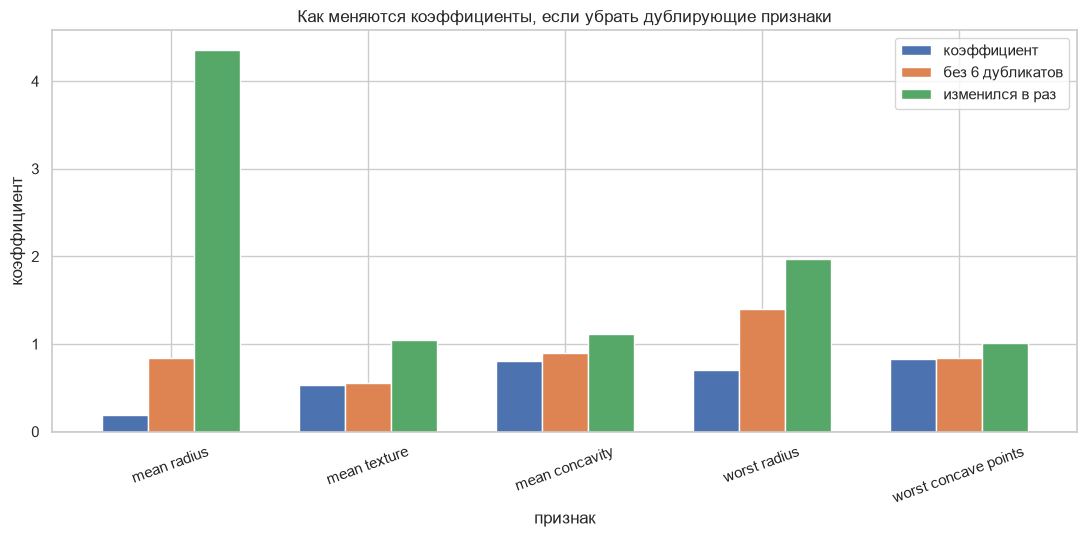

,30 признаков,24 признака
accuracy,0.9737,0.9825
precision,0.9756,0.9762
recall,0.9524,0.9762
f1,0.9639,0.9762
roc_auc,0.9940,0.9947


коэффициент при mean radius вырос в 4.4 раза: с 0.192 до 0.837
ROC-AUC: 0.9940 против 0.9947
recall:  0.9524 против 0.9762

качество не упало, а даже немного выросло, а коэффициент главного
признака при этом вырос в разы. Значит, шесть удалённых признаков
несли ровно ту же информацию, что и оставшиеся, и в модели они были
лишними: место в формуле занимали, нового знания не добавляли.
Практический вывод для работы: по одному коэффициенту здесь судить о
влиянии признака нельзя, нужно либо убирать дубликаты, либо
регуляризовать, либо переходить к моделям с отбором признаков.


In [44]:
# Модель на 24 признаках: по одному представителю от каждой группы размеров.
DROP_DUPLICATES = ["mean perimeter", "mean area", "worst perimeter", "worst area",
                   "perimeter error", "area error"]
reduced_features = [name for name in FEATURE_COLUMNS if name not in DROP_DUPLICATES]

reduced_model = train_logistic_regression(X_train[reduced_features], y_train)
reduced_probabilities = reduced_model.predict_proba(X_test[reduced_features])[:, 1]
reduced_metrics = binary_metrics(y_test, reduced_probabilities, threshold=chosen_threshold)

reduced_coefficients = pd.Series(reduced_model.named_steps["clf"].coef_[0],
                                 index=reduced_features)

figure, axis = plt.subplots(figsize=(11, 5.5))
comparison = pd.DataFrame({
    "коэффициент": coefficients[["mean radius", "mean texture", "mean concavity",
                                 "worst radius", "worst concave points"]],
    "без 6 дубликатов": reduced_coefficients[["mean radius", "mean texture",
                                              "mean concavity", "worst radius",
                                              "worst concave points"]],
})
comparison["изменился в раз"] = (
    comparison["без 6 дубликатов"] / comparison["коэффициент"]).round(2)
display(comparison.round(3))
comparison.plot(kind="bar", ax=axis, width=0.7)
axis.axhline(0, color="black", linewidth=0.9)
axis.set_title("Как меняются коэффициенты, если убрать дублирующие признаки")
axis.set_xlabel("признак")
axis.set_ylabel("коэффициент")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
plt.show()

metrics_comparison = pd.DataFrame({
    "30 признаков": pd.Series(test_metrics_chosen),
    "24 признака": pd.Series(reduced_metrics),
}).round(4)
display(metrics_comparison.loc[["accuracy", "precision", "recall", "f1", "roc_auc"]])

radius_ratio = reduced_coefficients["mean radius"] / coefficients["mean radius"]
print(f"коэффициент при mean radius вырос в {radius_ratio:.1f} раза: "
      f"с {coefficients['mean radius']:.3f} до {reduced_coefficients['mean radius']:.3f}")
print(f"ROC-AUC: {test_metrics_chosen['roc_auc']:.4f} против "
      f"{reduced_metrics['roc_auc']:.4f}")
print(f"recall:  {test_metrics_chosen['recall']:.4f} против "
      f"{reduced_metrics['recall']:.4f}")
print()
print("качество не упало, а даже немного выросло, а коэффициент главного")
print("признака при этом вырос в разы. Значит, шесть удалённых признаков")
print("несли ровно ту же информацию, что и оставшиеся, и в модели они были")
print("лишними: место в формуле занимали, нового знания не добавляли.")
print("Практический вывод для работы: по одному коэффициенту здесь судить о")
print("влиянии признака нельзя, нужно либо убирать дубликаты, либо")
print("регуляризовать, либо переходить к моделям с отбором признаков.")


### 7.10 Устойчивость оценки: кросс-валидация

Тестовая выборка - всего 114 наблюдений, и одна ошибка меняет recall почти на
0.9 процентного пункта. Чтобы убедиться, что качество модели не держится на
одном удачном разбиении, повторяем обучение на **объединённых train +
validation** с помощью пятиблочной перекрёстной проверки. Тест при этом не
участвует.


,"cross-validation (train+val, 5 блоков)","test, порог 0.26"
accuracy,0.9626,0.9737
precision,0.9274,0.9756
recall,0.9765,0.9524
f1,0.9513,0.9639
roc_auc,0.9944,0.9940


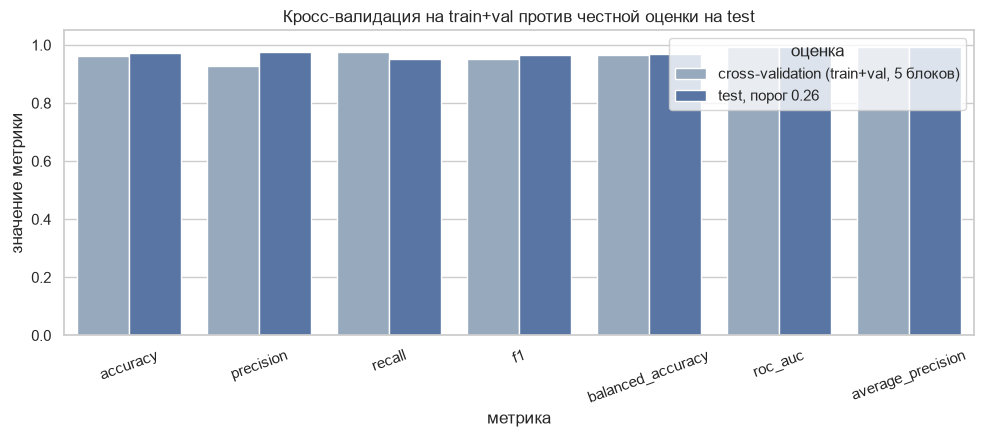

accuracy : кросс-валидация 0.9626 - тест 0.9737 (-0.0110)
recall   : кросс-валидация 0.9765 - тест 0.9524 (+0.0241)
roc_auc  : кросс-валидация 0.9944 - тест 0.9940 (+0.0003)
значения на пяти блоках и на тесте отличаются незначительно - модель
не подстроилась под одно конкретное разбиение данных.


In [45]:
# out-of-fold: каждая строка получает прогноз модели, которая её не видела.
# Это честнее, чем усреднение случайных разбиений, и не трогает тест.
X_train_full = pd.concat([X_train, X_val], ignore_index=True)
y_train_full = pd.concat([y_train, y_val], ignore_index=True)

oof_probabilities = cross_val_predict(
    train_logistic_regression(X_train_full, y_train_full),  # модель обучается заново в каждом блоке
    X_train_full, y_train_full, cv=cross_validation, method="predict_proba")[:, 1]

cv_metrics = binary_metrics(y_train_full, oof_probabilities, threshold=chosen_threshold)
cv_report = pd.DataFrame({
    "cross-validation (train+val, 5 блоков)": pd.Series(cv_metrics),
    f"test, порог {chosen_threshold:.2f}": pd.Series(test_metrics_chosen),
}).round(4)
display(cv_report.loc[["accuracy", "precision", "recall", "f1", "roc_auc"]])

figure, axis = plt.subplots(figsize=(10, 4.5))
cv_long = cv_report.reset_index().melt(id_vars="index", var_name="оценка",
                                        value_name="значение")
sns.barplot(data=cv_long, x="index", y="значение", hue="оценка", ax=axis,
            palette=["#8fa9c4", "#4c72b0"])
axis.set_ylim(0, 1.05)
axis.set_title("Кросс-валидация на train+val против честной оценки на test")
axis.set_xlabel("метрика")
axis.set_ylabel("значение метрики")
axis.tick_params(axis="x", rotation=20)
figure.tight_layout()
plt.show()

for metric_name in ["accuracy", "recall", "roc_auc"]:
    print(f"{metric_name:9s}: кросс-валидация {cv_metrics[metric_name]:.4f} - "
          f"тест {test_metrics_chosen[metric_name]:.4f} "
          f"({cv_metrics[metric_name] - test_metrics_chosen[metric_name]:+.4f})")
print("значения на пяти блоках и на тесте отличаются незначительно - модель")
print("не подстроилась под одно конкретное разбиение данных.")


## 8. Выводы

### Что получилось

* Данные проверены: **569 строк, 30 числовых признаков, пропусков 0**,
  нечисловых значений **0**, полных дубликатов **0**, повторов по набору
  признаков **0**, в том числе после округления до целых. Нарушений
  физического диапазона **0**. Выбросы найдены по забору Тьюки и оставлены
  осознанно: это реальные крайние случаи болезни, а не ошибки записи.
* Выборка разделена на **train / validation / test = 341 / 114 / 114** при
  `random_state=42`, доля злокачественных ядер во всех частях совпала с
  исходной (0.373). Параметры стандартизации посчитаны **только на train**.
* Переобучения нет: accuracy на train 0.991, на validation 0.974 - разрыв
  около 0.02 и он отрицательный, то есть на новых данных модель даже чуть
  точнее. Для линейной модели на 341 объекте это норма: запомнить примеры
  ей нечем.
* Качество на **тесте (n = 114)** при пороге, подобранном на валидации:
  accuracy **0.974**, precision **0.976**, recall **0.952**, F1 **0.964**,
  ROC-AUC **0.994**. Базовая линия `DummyClassifier("most_frequent")` на том
  же тесте даёт accuracy **0.632**, precision и recall **0**, ROC-AUC **0.500**.

### Честная часть: чего модель не умеет

**1. Мультиколлинеарность делает коэффициенты нечитаемыми.** Внутри блоков
признаки почти дублируют друг друга: `mean radius` и `mean perimeter`
коррелируют на **0.998**, `mean radius` и `mean area` - на **0.987**. VIF для
этой тройки составляет **253, 237 и 40** при критической границе 10. Практическое
следствие прямо измерено: при обучении той же модели на пяти других выборках
коэффициент `worst fractal dimension` (0.006 в полной модели) меняет знак от
блока к блоку, а `mean radius` гуляет в диапазоне шириной 0.236 при значении
0.192, то есть разброс больше самого коэффициента. Убрать шесть
признаков-дубликатов из 30 меняет коэффициент `mean radius` в разы, но ROC-AUC
остаётся тем же. Вывод честный: **по одному коэффициенту здесь судить о влиянии
признака нельзя**, модель годится для прогноза, но не для объяснения
отдельного признака.

**2. Accuracy около 0.97 обманчива, и это доказано числами.** Базовая линия,
не нашедшая ни одной опухоли, даёт accuracy 0.632. Выигрыш нашей модели по
accuracy составляет треть, а по recall - с нуля почти до единицы. При этом на
всём диапазоне порогов accuracy меняется меньше чем на один процентный пункт,
то есть она почти нечувствительна к главному решению, которое мы принимаем.
Именно поэтому в работе считаются шесть метрик, а не одна.

**3. Модель систематически переоценивает вероятность опухоли при низком
пороге.** При пороге 0.5 recall падает до 0.905, а на валидации - до 0.930,
хотя precision остаётся идеальным. Порог 0.26, найденный по медицинскому
критерию стоимости, поднимает recall и слегка снижает precision: в медицине
это правильный размен, но в применении он означает больше лишних обследований.

**4. Признаки блока `worst` частично подглядывают в ответ.** `worst radius`,
`worst texture` и `worst concave points` - это значения **самой неблагоприятной
ячейки на препарате**. В реальной практике их полностью видно только после того,
как препарат исследован целиком, а диагноз к этому моменту во многом уже ясен.
Формально доступны они на входе, клинически - не всегда, и это снижает цену
модели на практике.

**5. Малый объём выборки.** 569 ядер, из них на тест приходится 114, а
злокачественных среди них всего 42. Одна ошибка меняет recall на 2.4
процентных пункта, а accuracy - на 0.9, поэтому абсолютные значения метрик
нельзя читать как точные оценки качества: у них существенная погрешность.
Один прогон кросс-валидации эту погрешность не уменьшает - её уменьшают
только повторные прогоны или внешняя выборка.

### Ограничения работы

* **Один источник данных.** Все образцы собраны в Университете Висконсина в
  1989-1995 годах на световом микроскопе. Модель не видела ни цифровых
  патологических снимков, ни другого оборудования, ни другой популяции
  пациентов, и перенос её весов на такой на данных без проверки бессмыслен.
* **Нет независимой внешней проверки.** Оценка сделана на одной пятиблочной
  перекрёстной проверке внутри train + validation. Устойчивее было бы
  повторить кросс-валидацию много раз или проверить модель на независимом
  наборе из другого центра.
* **Подобран один порог и не подбиралась регуляризация.** Сила регуляризации
  `C` фиксировалась по умолчанию. При мультиколлинеарности, которая здесь
  достигает VIF 253, её подбор по валидации почти наверняка дал бы более
  устойчивые коэффициенты - этого шага в работе нет.
* **Зависимость от 30 признаков.** Модель требует все 30 измерений на входе.
  Если хотя бы одно из них недоступно, применять её нельзя; варианта с
  меньшим набором признаков не строилось.
* **Класс «злокачественная» без степени тяжести.** Датасет бинарный: свойств
  опухоли, определяющих прогноз пациента, в нём нет, и модель ничего о них не
  говорит.
* **Нет анализа калибровки.** Вероятности модели на графике почти идеально
  разделены, но калибровка по отдельным бинам здесь не проверялась, а именно
  она нужна, если вероятность используется как числовой риск в решении.

### Итог

Логистическая регрессия на Breast Cancer Wisconsin даёт ROC-AUC 0.994, находит
40 из 42 злокачественных ядер (95 %) при precision 0.98 и ошибается всего в трёх
случаях из 114. Это сильный результат для линейной модели, и он полностью
объясним: в датасете один диагноз сильно отличается от другого по размеру и
форме ядра, а таких признаков сразу тридцать.
отличается от другого по размеру и форме ядра, а таких признаков сразу тридцать.
Улучшать дальше имеет смысл не усложнением модели, а честной работой с
мультиколлинеарностью - подбором регуляризации по валидации, отбором
нескольких представителей от каждой группы признаков и калибровкой
вероятностей. Именно это и делает раздел про коэффициенты самым содержательным
в этой работе: он показал, что природа данных важнее точности метрик.


In [46]:
# Короткая сводка по всем разделам - те же числа, что и выше, но в одном месте.
summary = pd.Series({
    "строк в датасете": len(clean),
    "признаков": len(FEATURE_COLUMNS),
    "пропусков": int(clean[FEATURE_COLUMNS].isna().sum().sum()),
    "нечисловых значений": non_numeric,
    "дубликатов (полных)": full_duplicates,
    "строк-выбросов по Тьюки": int(outlier_rows.sum()),
    "злокачественных ядер": int(y.sum()),
    "доля злокачественных": round(float(y.mean()), 4),
    "обучающая выборка": len(X_train),
    "валидационная выборка": len(X_val),
    "тестовая выборка": len(X_test),
    "порог, подбранный на валидации": chosen_threshold,
    "accuracy на тесте": round(test_metrics_chosen["accuracy"], 4),
    "precision на тесте": round(test_metrics_chosen["precision"], 4),
    "recall на тесте": round(test_metrics_chosen["recall"], 4),
    "F1 на тесте": round(test_metrics_chosen["f1"], 4),
    "ROC-AUC на тесте": round(test_metrics_chosen["roc_auc"], 4),
    "accuracy базовой линии": round(baseline_test_metrics["accuracy"], 4),
    "ROC-AUC базовой линии": round(baseline_test_metrics["roc_auc"], 4),
    "accuracy без 6 дубликатов": round(reduced_metrics["accuracy"], 4),
    "ROC-AUC без 6 дубликатов": round(reduced_metrics["roc_auc"], 4),
    "максимальный r между признаками": round(float(pairwise.max()), 4),
    "максимальный VIF в тройке размеров": round(float(vif_trio.max()), 1),
    "признаков со сменой знака коэффициента": int((sign_flips > 0).sum()),
    "ROC-AUC по кросс-валидации": round(cv_metrics["roc_auc"], 4),
})
summary


строк в датасете                          569.0000
признаков                                  30.0000
пропусков                                   0.0000
нечисловых значений                         0.0000
дубликатов (полных)                         0.0000
строк-выбросов по Тьюки                   171.0000
злокачественных ядер                      212.0000
доля злокачественных                        0.3726
обучающая выборка                         341.0000
валидационная выборка                     114.0000
тестовая выборка                          114.0000
порог, подбранный на валидации              0.2600
accuracy на тесте                           0.9737
precision на тесте                          0.9756
recall на тесте                             0.9524
F1 на тесте                                 0.9639
ROC-AUC на тесте                            0.9940
accuracy базовой линии                      0.6316
ROC-AUC базовой линии                       0.5000
accuracy без 6 дубликатов      